# Projeto de Machine Learning


In [193]:
import kagglehub
import pandas as pd
import os

# Baixa a versão mais recente (retorna o caminho da PASTA)
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")

print("Path to dataset files:", path)

# Monta o caminho completo até o arquivo CSV
arquivo_csv = os.path.join(path, "healthcare-dataset-stroke-data.csv")

# Cria a variável 'dataset' com o conteúdo do CSV
dataset = pd.read_csv(arquivo_csv)

# Confere que carregou certo
print(dataset.head())

Path to dataset files: C:\Users\adrie\.cache\kagglehub\datasets\fedesoriano\stroke-prediction-dataset\versions\1
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0  

In [194]:
# Só as colunas numéricas (int e float)
colunas_numericas = dataset.select_dtypes(include=["number"])

# Só as colunas NÃO numéricas (texto/categóricas)
colunas_nao_numericas = dataset.select_dtypes(exclude=["number"])


In [195]:
print(dataset.isnull().sum())


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [196]:
print(colunas_numericas.head())

      id   age  hypertension  heart_disease  avg_glucose_level   bmi  stroke
0   9046  67.0             0              1             228.69  36.6       1
1  51676  61.0             0              0             202.21   NaN       1
2  31112  80.0             0              1             105.92  32.5       1
3  60182  49.0             0              0             171.23  34.4       1
4   1665  79.0             1              0             174.12  24.0       1


In [197]:
print(colunas_nao_numericas.head())

   gender ever_married      work_type Residence_type   smoking_status
0    Male          Yes        Private          Urban  formerly smoked
1  Female          Yes  Self-employed          Rural     never smoked
2    Male          Yes        Private          Rural     never smoked
3  Female          Yes        Private          Urban           smokes
4  Female          Yes  Self-employed          Rural     never smoked


In [198]:
# Mostra nome de cada coluna, quantos valores únicos tem, e exemplos de valores
for coluna in dataset.columns:
    print(f"Coluna: {coluna}")
    print(f"  Tipo: {dataset[coluna].dtype}")
    print(f"  Valores únicos: {dataset[coluna].nunique()}")
    print(f"  Exemplos: {dataset[coluna].unique()[:5]}")
    print()

Coluna: id
  Tipo: int64
  Valores únicos: 5110
  Exemplos: [ 9046 51676 31112 60182  1665]

Coluna: gender
  Tipo: object
  Valores únicos: 3
  Exemplos: ['Male' 'Female' 'Other']

Coluna: age
  Tipo: float64
  Valores únicos: 104
  Exemplos: [67. 61. 80. 49. 79.]

Coluna: hypertension
  Tipo: int64
  Valores únicos: 2
  Exemplos: [0 1]

Coluna: heart_disease
  Tipo: int64
  Valores únicos: 2
  Exemplos: [1 0]

Coluna: ever_married
  Tipo: object
  Valores únicos: 2
  Exemplos: ['Yes' 'No']

Coluna: work_type
  Tipo: object
  Valores únicos: 5
  Exemplos: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Coluna: Residence_type
  Tipo: object
  Valores únicos: 2
  Exemplos: ['Urban' 'Rural']

Coluna: avg_glucose_level
  Tipo: float64
  Valores únicos: 3979
  Exemplos: [228.69 202.21 105.92 171.23 174.12]

Coluna: bmi
  Tipo: float64
  Valores únicos: 418
  Exemplos: [36.6  nan 32.5 34.4 24. ]

Coluna: smoking_status
  Tipo: object
  Valores únicos: 4
  Exemplos: ['forme

In [199]:
# Conta valores ausentes (NaN) por coluna
print("Valores ausentes por coluna:")
print(dataset.isnull().sum())

# Mostra a porcentagem de ausentes por coluna (mais fácil de interpretar)
print("\nPorcentagem de ausentes por coluna:")
print((dataset.isnull().sum() / len(dataset) * 100).round(2))

Valores ausentes por coluna:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Porcentagem de ausentes por coluna:
id                   0.00
gender               0.00
age                  0.00
hypertension         0.00
heart_disease        0.00
ever_married         0.00
work_type            0.00
Residence_type       0.00
avg_glucose_level    0.00
bmi                  3.93
smoking_status       0.00
stroke               0.00
dtype: float64


In [200]:
# .shape devolve uma tupla (número de linhas, número de colunas)
print("Formato do dataset:", dataset.shape)
print("Número de instâncias (linhas):", dataset.shape[0])
print("Número de features (colunas):", dataset.shape[1])

Formato do dataset: (5110, 12)
Número de instâncias (linhas): 5110
Número de features (colunas): 12


In [201]:
# Visão geral: tipo de cada coluna + contagem de não-nulos, tudo de uma vez
dataset.info()

# Separando explicitamente pelos tipos (usando o select_dtypes que já vimos)
colunas_numericas = dataset.select_dtypes(include=["number"]).columns.tolist()
colunas_categoricas = dataset.select_dtypes(exclude=["number"]).columns.tolist()


# Nas categóricas: ver todos os valores possíveis, procurando categorias estranhas
for coluna in colunas_categoricas:
    print(f"{coluna}: {dataset[coluna].unique()}")

# Nas numéricas: estatísticas (min, max, média) pra achar valores impossíveis
print(dataset.describe())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
gender: ['Male' 'Female' 'Other']
ever_married: ['Yes' 'No']
work_type: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type: ['Ur

In [202]:
# Contagem absoluta de cada classe na variável alvo
print("Contagem por classe (stroke):")
print(dataset["stroke"].value_counts())

# Proporção percentual de cada classe
print("\nProporção por classe (%):")
print((dataset["stroke"].value_counts(normalize=True) * 100).round(2))

Contagem por classe (stroke):
stroke
0    4861
1     249
Name: count, dtype: int64

Proporção por classe (%):
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


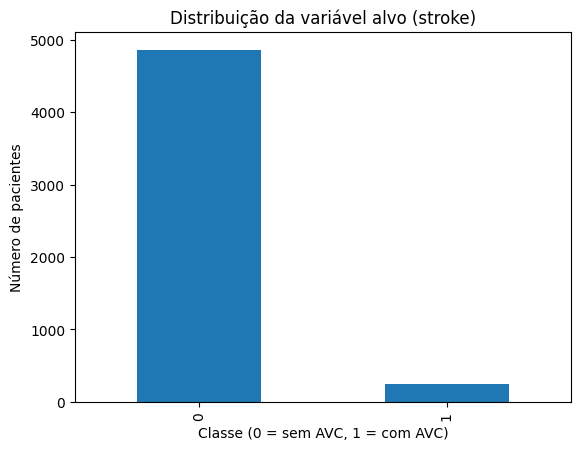

In [203]:
import matplotlib.pyplot as plt

dataset["stroke"].value_counts().plot(kind="bar")
plt.title("Distribuição da variável alvo (stroke)")
plt.xlabel("Classe (0 = sem AVC, 1 = com AVC)")
plt.ylabel("Número de pacientes")
plt.show()

In [204]:
# Conta a incidência de 'Unknown' na coluna 'smoking_status'
unknown_smoking = dataset['smoking_status'].value_counts().get('Unknown', 0)
print(f"Número de 'Unknown' em smoking_status: {unknown_smoking}")

# Conta a incidência de 'Other' na coluna 'gender'
other_gender = dataset['gender'].value_counts().get('Other', 0)
print(f"Número de 'Other' em gender: {other_gender}")

Número de 'Unknown' em smoking_status: 1544
Número de 'Other' em gender: 1


### Verificando Valores Nulos (NaN) e `None`

Conforme já vimos, o método `.isnull().sum()` é a forma padrão de verificar a quantidade de valores `NaN` (Not a Number) em cada coluna de um DataFrame do pandas.

In [205]:
# Verificando valores NaN (Not a Number)
print('Contagem de valores NaN por coluna:')
display(dataset.isnull().sum())

Contagem de valores NaN por coluna:


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

É importante notar que, em DataFrames do pandas, valores `None` (do Python) em colunas numéricas são geralmente convertidos para `NaN` automaticamente. Em colunas de tipo `object` (que contêm strings ou objetos diversos), `None` pode permanecer como `None`. Podemos verificar explicitamente por `None` se necessário, embora seja menos comum após a leitura de dados típicos.

In [206]:
# Verificando explicitamente por valores None em colunas do tipo 'object'
# (Pandas geralmente converte None para NaN em colunas numéricas)

print('\nContagem de valores None por coluna (apenas para colunas \'object\'):')
none_counts = {}
for col in dataset.select_dtypes(include='object').columns:
    none_counts[col] = (dataset[col] == None).sum()
display(pd.Series(none_counts))


Contagem de valores None por coluna (apenas para colunas 'object'):


gender            0
ever_married      0
work_type         0
Residence_type    0
smoking_status    0
dtype: int64

### Verificando Valores Zero

Agora, vamos verificar a presença de valores zero em cada coluna, pois em alguns contextos, zero pode ser considerado um valor 'ausente' ou atípico, dependendo do significado da coluna.

In [207]:
# Contagem de valores zero por coluna
print('\nContagem de valores zero por coluna:')
zero_counts = {}
for col in dataset.columns:
    # Para evitar erros com colunas de texto, verificamos apenas onde o tipo é numérico
    if pd.api.types.is_numeric_dtype(dataset[col]):
        zero_counts[col] = (dataset[col] == 0).sum()
    else:
        zero_counts[col] = 'Não aplicável (coluna não numérica)'
display(pd.Series(zero_counts))


Contagem de valores zero por coluna:


id                                                     0
gender               Não aplicável (coluna não numérica)
age                                                    0
hypertension                                        4612
heart_disease                                       4834
ever_married         Não aplicável (coluna não numérica)
work_type            Não aplicável (coluna não numérica)
Residence_type       Não aplicável (coluna não numérica)
avg_glucose_level                                      0
bmi                                                    0
smoking_status       Não aplicável (coluna não numérica)
stroke                                              4861
dtype: object

In [208]:
# Filtrando o dataset para mostrar linhas onde 'bmi' é igual a zero
bmi_zero_df = dataset[dataset['bmi'] == 0]

print("Linhas onde 'bmi' é zero (primeiras 10):")
display(bmi_zero_df.head(10))

Linhas onde 'bmi' é zero (primeiras 10):


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke


In [209]:
# Filtrando o dataset para mostrar linhas onde 'bmi' é NaN (nulo)
bmi_nan_df = dataset[dataset['bmi'].isnull()]

print("Linhas onde 'bmi' é NaN (primeiras 10):")
display(bmi_nan_df.head(10))

Linhas onde 'bmi' é NaN (primeiras 10):


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,61843,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1
29,69160,Male,59.0,0,0,Yes,Private,Rural,211.78,NaN,formerly smoked,1
43,1845,Female,63.0,0,0,Yes,Private,Urban,90.90,NaN,formerly smoked,1
46,37937,Female,75.0,0,1,No,Self-employed,Urban,109.78,NaN,Unknown,1
50,18587,Female,76.0,0,0,No,Private,Urban,89.96,NaN,Unknown,1
51,15102,Male,78.0,1,0,Yes,Private,Urban,75.32,NaN,formerly smoked,1


### Verificando Consistência dos Dados

Vamos agora verificar se há valores nas colunas numéricas que estão fora de um range considerado válido, indicando possíveis erros na coleta ou registro dos dados.

#### Consistência da Coluna `age`

Vamos verificar idades abaixo de 0 ou acima de 121 anos (um limite comum para a idade humana).

In [210]:
# Verificando 'age' fora da faixa (abaixo de 0 ou acima de 121)
inconsistent_age = dataset[(dataset['age'] < 0) | (dataset['age'] > 121)]

print("Linhas com 'age' inconsistente:")
if not inconsistent_age.empty:
    display(inconsistent_age)
else:
    print("Nenhuma idade inconsistente encontrada.")

Linhas com 'age' inconsistente:
Nenhuma idade inconsistente encontrada.


#### Consistência da Coluna `avg_glucose_level`

Para `avg_glucose_level`, consideraremos valores fora da faixa de 30 mg/dL (hipoglicemia severa) a 600 mg/dL (hiperglicemia severa) como potencialmente inconsistentes, embora limites clínicos específicos possam variar.

In [211]:
# Verificando 'avg_glucose_level' fora da faixa (ex: < 30 ou > 600)
inconsistent_glucose = dataset[(dataset['avg_glucose_level'] < 30) | (dataset['avg_glucose_level'] > 600)]

print("Linhas com 'avg_glucose_level' inconsistente:")
if not inconsistent_glucose.empty:
    display(inconsistent_glucose)
else:
    print("Nenhum nível de glicose inconsistente encontrado.")

Linhas com 'avg_glucose_level' inconsistente:
Nenhum nível de glicose inconsistente encontrado.


#### Consistência da Coluna `bmi`

Para `bmi`, vamos verificar valores abaixo de 10 (considerado subnutrição extrema) ou acima de 80 (obesidade mórbida extrema), que são raros na população geral.

In [212]:
# Verificando 'bmi' fora da faixa (ex: < 10 ou > 80)
inconsistent_bmi = dataset[(dataset['bmi'] < 10) | (dataset['bmi'] > 80)]

print("Linhas com 'bmi' inconsistente:")
if not inconsistent_bmi.empty:
    display(inconsistent_bmi)
else:
    print("Nenhum BMI inconsistente encontrado.")

Linhas com 'bmi' inconsistente:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2128,56420,Male,17.0,1,0,No,Private,Rural,61.67,97.6,Unknown,0
4209,51856,Male,38.0,1,0,Yes,Private,Rural,56.90,92.0,never smoked,0


### Contagem de Incidências para Colunas Categóricas

Vamos agora verificar a distribuição de cada categoria nas colunas não numéricas para identificar desbalanceamentos ou categorias com poucos exemplos.

In [213]:
print("Contagem de incidências por categoria nas colunas categóricas:\n")
for coluna in colunas_categoricas:
    print(f"Coluna: {coluna}")
    display(dataset[coluna].value_counts())
    print("\n" + "-" * 50 + "\n")

Contagem de incidências por categoria nas colunas categóricas:

Coluna: gender


gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


--------------------------------------------------

Coluna: ever_married


ever_married
Yes    3353
No     1757
Name: count, dtype: int64


--------------------------------------------------

Coluna: work_type


work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64


--------------------------------------------------

Coluna: Residence_type


Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64


--------------------------------------------------

Coluna: smoking_status


smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


--------------------------------------------------



### Contagem de Zeros e Uns em Colunas Numéricas

Agora vamos verificar a contagem de 0s e 1s nas colunas numéricas que geralmente representam categorias binárias ou a variável alvo (`stroke`), para entender o balanceamento desses valores.

In [214]:
print("Contagem de Zeros e Uns por Coluna (numéricas binárias):\n")

# Filtra as colunas que são numéricas e que contêm apenas 0 e 1 (ou predominantemente)
# Excluímos 'id' e 'age' e 'avg_glucose_level' e 'bmi' pois são contínuas ou IDs
binary_numeric_columns = ['hypertension', 'heart_disease', 'stroke']

for coluna in binary_numeric_columns:
    print(f"Coluna: {coluna}")
    zero_count = (dataset[coluna] == 0).sum()
    one_count = (dataset[coluna] == 1).sum()

    print(f"  Contagem de 0: {zero_count}")
    print(f"  Contagem de 1: {one_count}")

    # Calcula a porcentagem
    total_count = zero_count + one_count
    if total_count > 0:
        zero_percent = (zero_count / total_count) * 100
        one_percent = (one_count / total_count) * 100
        print(f"  Porcentagem de 0: {zero_percent:.2f}%")
        print(f"  Porcentagem de 1: {one_percent:.2f}%")
    else:
        print("  (Não há valores 0 ou 1 nesta coluna)")
    print("\n" + "-" * 50 + "\n")


Contagem de Zeros e Uns por Coluna (numéricas binárias):

Coluna: hypertension
  Contagem de 0: 4612
  Contagem de 1: 498
  Porcentagem de 0: 90.25%
  Porcentagem de 1: 9.75%

--------------------------------------------------

Coluna: heart_disease
  Contagem de 0: 4834
  Contagem de 1: 276
  Porcentagem de 0: 94.60%
  Porcentagem de 1: 5.40%

--------------------------------------------------

Coluna: stroke
  Contagem de 0: 4861
  Contagem de 1: 249
  Porcentagem de 0: 95.13%
  Porcentagem de 1: 4.87%

--------------------------------------------------



In [215]:
# Seleciona só as colunas numéricas
numericas = dataset.select_dtypes(include="number")

# Monta uma tabela com as três estatísticas pedidas, uma coluna cada
estatisticas = pd.DataFrame({
    "média": numericas.mean(),
    "mediana": numericas.median(),
    "desvio_padrão": numericas.std()
})

print(estatisticas.round(2))

                      média   mediana  desvio_padrão
id                 36517.83  36932.00       21161.72
age                   43.23     45.00          22.61
hypertension           0.10      0.00           0.30
heart_disease          0.05      0.00           0.23
avg_glucose_level    106.15     91.88          45.28
bmi                   28.89     28.10           7.85
stroke                 0.05      0.00           0.22


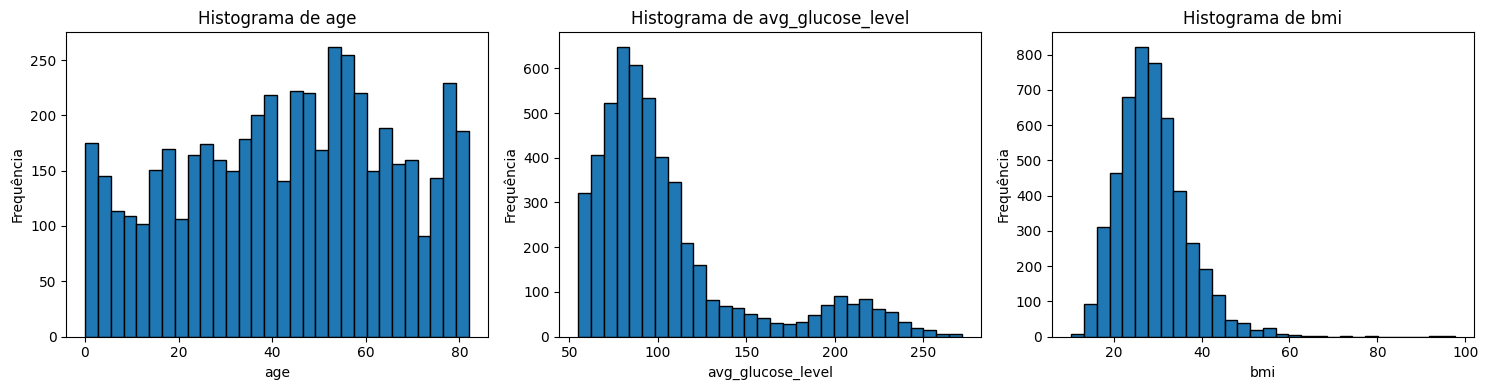

In [216]:
import matplotlib.pyplot as plt

variaveis_continuas = ["age", "avg_glucose_level", "bmi"]

# Cria uma figura com 3 gráficos lado a lado (1 linha, 3 colunas)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, coluna in enumerate(variaveis_continuas):
    axes[i].hist(dataset[coluna].dropna(), bins=30, edgecolor="black")
    axes[i].set_title(f"Histograma de {coluna}")
    axes[i].set_xlabel(coluna)
    axes[i].set_ylabel("Frequência")

plt.tight_layout()
plt.show()

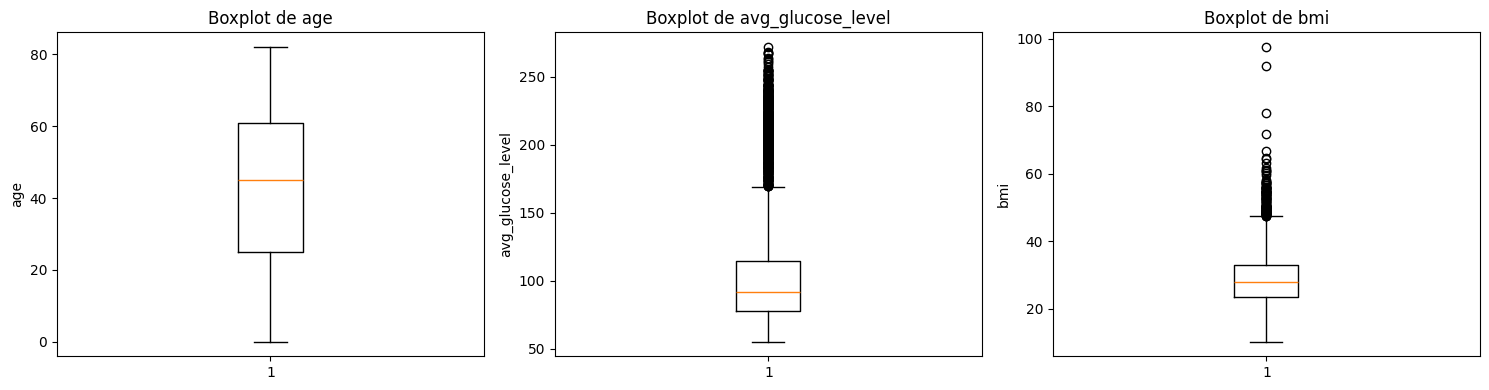

In [217]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, coluna in enumerate(variaveis_continuas):
    axes[i].boxplot(dataset[coluna].dropna())
    axes[i].set_title(f"Boxplot de {coluna}")
    axes[i].set_ylabel(coluna)

plt.tight_layout()
plt.show()

In [218]:
for coluna in colunas_categoricas:
    print(f"\n=== {coluna} ===")
    print("Contagem:")
    print(dataset[coluna].value_counts())
    print("\nPorcentagem (%):")
    print((dataset[coluna].value_counts(normalize=True) * 100).round(2))


=== gender ===
Contagem:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Porcentagem (%):
gender
Female    58.59
Male      41.39
Other      0.02
Name: proportion, dtype: float64

=== ever_married ===
Contagem:
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

Porcentagem (%):
ever_married
Yes    65.62
No     34.38
Name: proportion, dtype: float64

=== work_type ===
Contagem:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Porcentagem (%):
work_type
Private          57.24
Self-employed    16.03
children         13.44
Govt_job         12.86
Never_worked      0.43
Name: proportion, dtype: float64

=== Residence_type ===
Contagem:
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

Porcentagem (%):
Residence_type
Urban    50.8
Rural    49.2
Name: proportion, dtype: float64

=== smoking_status ===
Contagem:
smoking_status
never sm

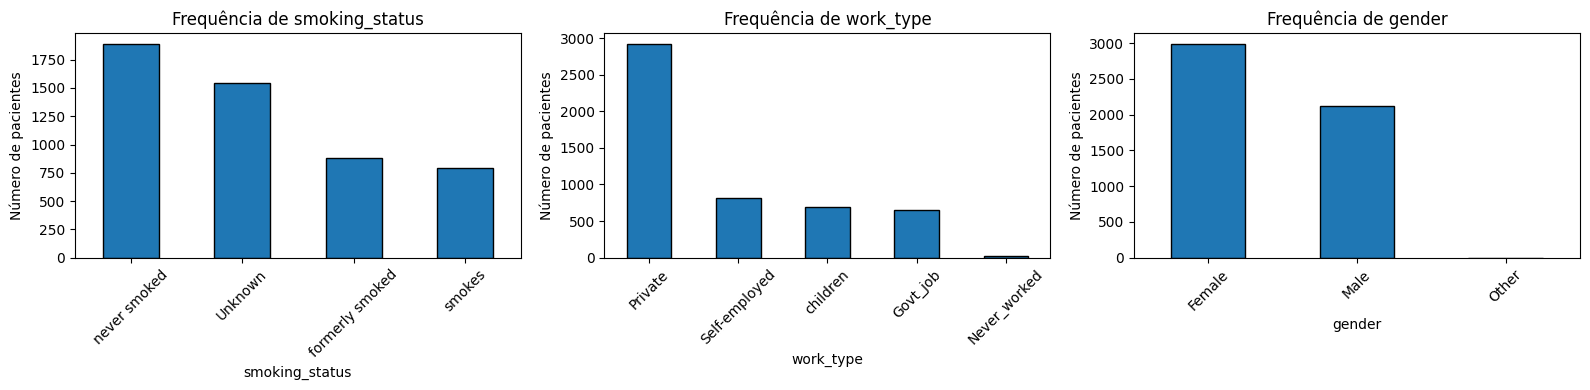

In [219]:
categoricas_grafico = ["smoking_status", "work_type", "gender"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, coluna in enumerate(categoricas_grafico):
    dataset[coluna].value_counts().plot(kind="bar", ax=axes[i], edgecolor="black")
    axes[i].set_title(f"Frequência de {coluna}")
    axes[i].set_xlabel(coluna)
    axes[i].set_ylabel("Número de pacientes")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Resolvendo `NameError`: Recarregando Dados

O erro `NameError` indica que o notebook pode ter sido executado fora de ordem ou o kernel foi reiniciado, fazendo com que as variáveis `dataset`, `colunas_numericas` e `colunas_categoricas` não estivessem definidas. Esta célula recarregará os dados e redefinirá essas variáveis essenciais para que as etapas subsequentes possam ser executadas.

In [220]:
import kagglehub
import pandas as pd
import os

# Recarrega o dataset para garantir que esteja definido
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
arquivo_csv = os.path.join(path, "healthcare-dataset-stroke-data.csv")
dataset = pd.read_csv(arquivo_csv)

# Redefine as listas de colunas numéricas e categóricas
colunas_numericas = dataset.select_dtypes(include=["number"]).columns.tolist()
colunas_categoricas = dataset.select_dtypes(exclude=["number"]).columns.tolist()

print("Dataset e listas de colunas recarregados com sucesso.")

Dataset e listas de colunas recarregados com sucesso.


In [221]:
from sklearn.model_selection import train_test_split

# Remove id (identificador, sem valor preditivo) e separa target
X = dataset.drop(columns=['id', 'stroke'])
y = dataset['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y            # mantém ~5% de AVC em treino e teste
)

print('Treino:', X_train.shape, '| % AVC:', round(y_train.mean()*100, 2))
print('Teste :', X_test.shape,  '| % AVC:', round(y_test.mean()*100, 2))

Treino: (4088, 10) | % AVC: 4.87
Teste : (1022, 10) | % AVC: 4.89


In [222]:
train = X_train.copy()
train['stroke'] = y_train.values

num_cols = train.select_dtypes(include='number').columns.drop('stroke').tolist()
cat_cols = train.select_dtypes(exclude='number').columns.tolist()

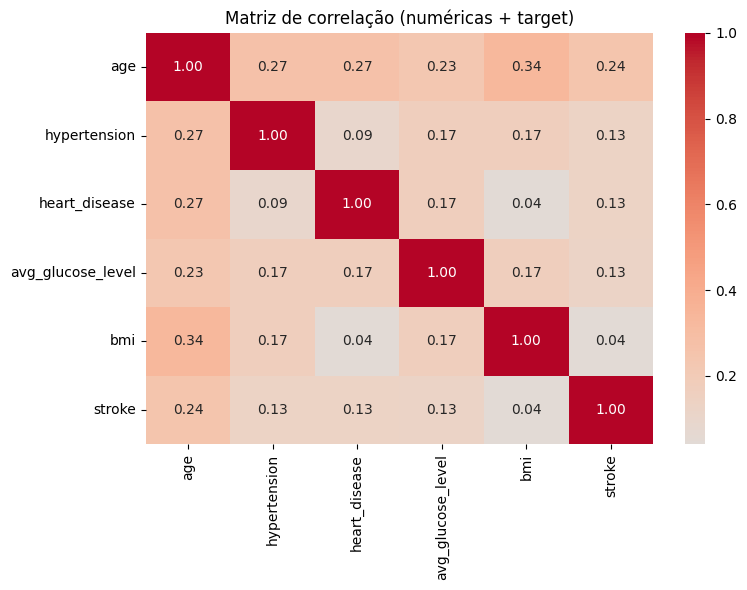

Correlação de cada numérica com stroke:
stroke               1.000
age                  0.243
hypertension         0.133
heart_disease        0.127
avg_glucose_level    0.125
bmi                  0.044
Name: stroke, dtype: float64


In [223]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(train[num_cols + ['stroke']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação (numéricas + target)')
plt.tight_layout()
plt.show()

print('Correlação de cada numérica com stroke:')
print(train[num_cols + ['stroke']].corr()['stroke']
      .sort_values(ascending=False).round(3))

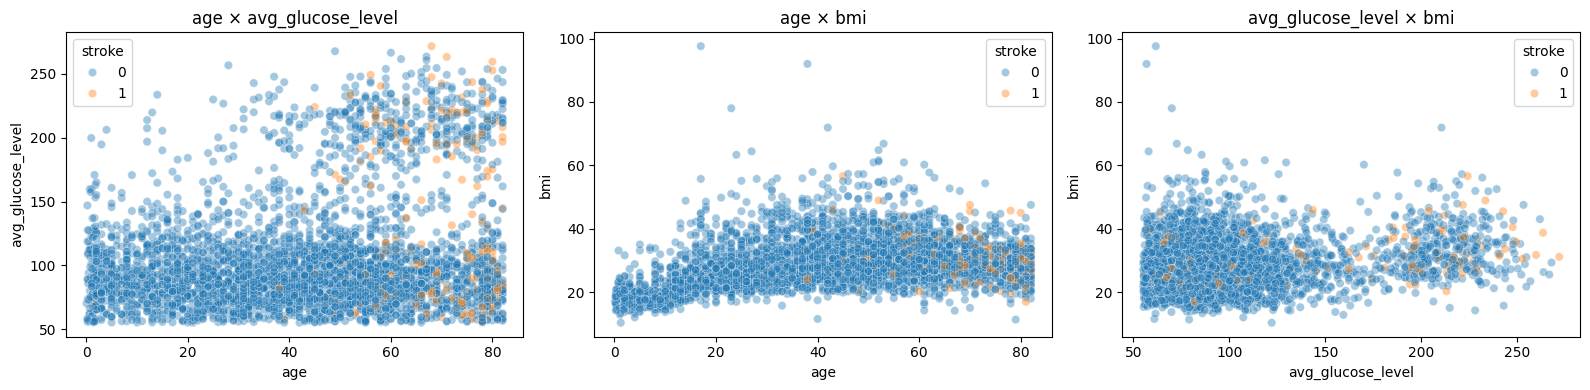

In [224]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=train, x='age', y='avg_glucose_level',
                hue='stroke', alpha=0.4, ax=axes[0])
sns.scatterplot(data=train, x='age', y='bmi',
                hue='stroke', alpha=0.4, ax=axes[1])
sns.scatterplot(data=train, x='avg_glucose_level', y='bmi',
                hue='stroke', alpha=0.4, ax=axes[2])
for ax in axes:
    ax.set_title(ax.get_xlabel() + ' × ' + ax.get_ylabel())
plt.tight_layout()
plt.show()

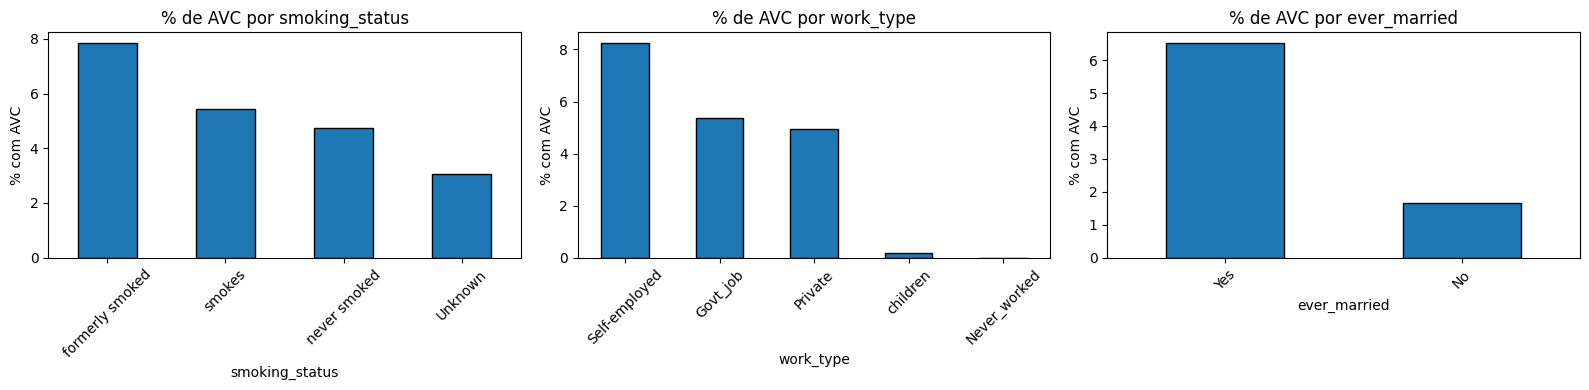

stroke,0,1
smoking_status,,
Unknown,0.970,0.030
formerly smoked,0.922,0.078
never smoked,0.953,0.047
smokes,0.946,0.054


In [225]:
cats_alvo = ['smoking_status', 'work_type', 'ever_married']  # escolha 3

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cats_alvo):
    taxa = (train.groupby(col)['stroke'].mean() * 100).sort_values(ascending=False)
    taxa.plot(kind='bar', ax=ax, edgecolor='black')
    ax.set_title(f'% de AVC por {col}')
    ax.set_ylabel('% com AVC')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Versão em tabela de contingência (proporção por linha)
pd.crosstab(train['smoking_status'], train['stroke'], normalize='index').round(3)

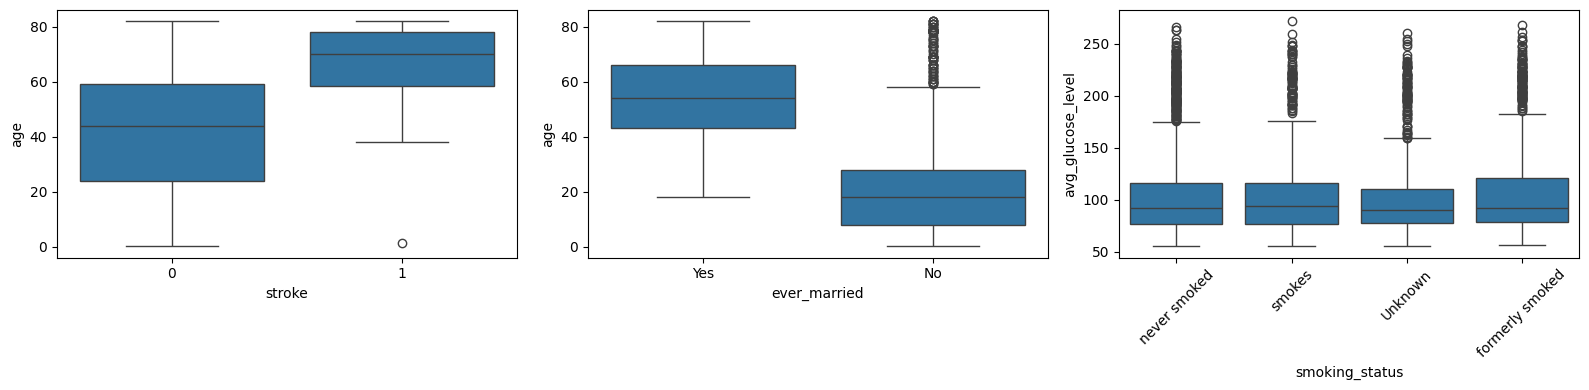

In [226]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=train, x='stroke', y='age', ax=axes[0])
sns.boxplot(data=train, x='ever_married', y='age', ax=axes[1])
sns.boxplot(data=train, x='smoking_status', y='avg_glucose_level', ax=axes[2])
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Pré-processamento dos Dados para Clustering

Vamos preparar os dados para o clustering, tratando valores inconsistentes, nulos, e aplicando transformações necessárias como codificação e escalonamento.

In [227]:
# LIDANDO COM CATEGORIAS IRREGULARES

# 1. Coluna 'gender': Substituir 'Other' pela categoria mais frequente ('Female')
# Verificamos que 'Other' tem apenas 1 ocorrência.
# Antes de substituir, vamos verificar a contagem atual.
print("Contagem de 'gender' antes da correção:")
display(X['gender'].value_counts())

X['gender'] = X['gender'].replace('Other', 'Female')

print("\nContagem de 'gender' depois da correção:")
display(X['gender'].value_counts())

# 2. Coluna 'smoking_status': 'Unknown' será tratado como uma categoria separada
# mas é importante estar ciente de sua alta incidência.
# Não faremos alteração direta aqui, mas a codificação One-Hot cuidará disso.

Contagem de 'gender' antes da correção:


gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


Contagem de 'gender' depois da correção:


gender
Female    2995
Male      2115
Name: count, dtype: int64

### Imputação de Valores Nulos (NaN) para `bmi`

A coluna `bmi` possui valores nulos. Vamos preenchê-los com a mediana da coluna, que é mais robusta a outliers do que a média.

In [228]:
from sklearn.impute import SimpleImputer

# Cria uma cópia de X para não modificar o DataFrame original diretamente antes de todas as etapas
X_processed = X.copy()

# Imputação da mediana para 'bmi'
imputer_bmi = SimpleImputer(strategy='median')
X_processed['bmi'] = imputer_bmi.fit_transform(X_processed[['bmi']])

print("Valores nulos em 'bmi' após imputação:")
display(X_processed['bmi'].isnull().sum())

Valores nulos em 'bmi' após imputação:


np.int64(0)

### Codificação de Variáveis Categóricas e Escalonamento de Variáveis Numéricas

Utilizaremos `OneHotEncoder` para as variáveis categóricas e `StandardScaler` para as variáveis numéricas. Para organizar essas transformações, construiremos um `ColumnTransformer`.

In [229]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identifica colunas numéricas e categóricas para o pré-processamento
# 'id' já foi removido de X

# Certifique-se de que 'colunas_numericas' e 'colunas_categoricas' refletem o DataFrame X_processed
# e não incluem o target 'stroke' se ainda estivesse lá.

# Atualiza as listas de colunas com base no X_processed após a imputação de BMI
# Excluímos 'id' e 'stroke' que já foram separados

# colunas_numericas = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']
# colunas_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

# Re-obtem as listas de colunas de X_processed
# Removendo 'id' se ainda estivesse, embora já deva ter sido removido
num_features = X_processed.select_dtypes(include=['number']).columns.tolist()
cat_features = X_processed.select_dtypes(include=['object']).columns.tolist()

# Cria o ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])

# Aplica as transformações
X_scaled_encoded = preprocessor.fit_transform(X_processed)

print("Formato dos dados após codificação e escalonamento:", X_scaled_encoded.shape)

Formato dos dados após codificação e escalonamento: (5110, 20)


### Análise de Componentes Principais (PCA)

Para reduzir a dimensionalidade e facilitar o clustering, vamos aplicar PCA nos dados pré-processados. Isso pode ajudar a remover ruído e focar nas características mais importantes.

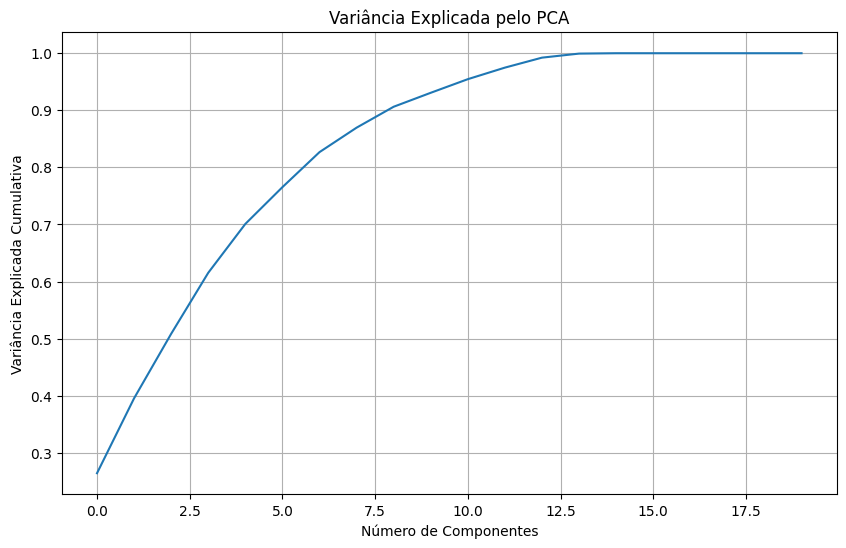

Formato dos dados após PCA com 10 componentes: (5110, 10)


In [230]:
import numpy as np
from sklearn.decomposition import PCA

# Determinar o número ideal de componentes pode ser feito com uma curva de variância explicada
pca = PCA().fit(X_scaled_encoded)

plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Número de Componentes')
plt.ylabel('Variância Explicada Cumulativa')
plt.title('Variância Explicada pelo PCA')
plt.grid(True)
plt.show()

# Vamos escolher um número de componentes que explique uma alta porcentagem da variância (ex: 95%)
# ou um número razoável para a visualização/interpretação.
# Para fins de exemplo, vamos começar com 10 componentes, mas o ideal seria analisar o gráfico.

n_components = 10 # Ajuste baseado na análise do gráfico acima
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled_encoded)

print(f"Formato dos dados após PCA com {n_components} componentes: {X_pca.shape}")

## Determinando o Número Ótimo de Clusters (k)

Utilizaremos dois métodos populares para encontrar o `k` ideal para o K-Means: o Método do Cotovelo (Elbow Method) e o Coeficiente de Silhueta (Silhouette Score).

Vamos começar importando as bibliotecas necessárias.

In [231]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Definir um intervalo de k para testar
k_range = range(2, 11) # Geralmente testamos de 2 até um número razoável de clusters

# Armazenar os resultados para o Método do Cotovelo
sum_of_squared_distances = []

# Armazenar os resultados para o Coeficiente de Silhueta
silhouette_scores = []

# Executar K-Means para cada valor de k e calcular as métricas
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    # !!! Alterado para usar X_scaled_encoded diretamente !!!
    kmeans.fit(X_scaled_encoded)
    sum_of_squared_distances.append(kmeans.inertia_)

    # Calcula o coeficiente de silhueta, mas apenas se houver mais de um cluster e mais de 1 amostra
    if k > 1:
        labels = kmeans.labels_
        # !!! Alterado para usar X_scaled_encoded para o silhouette_score !!!
        sil_avg = silhouette_score(X_scaled_encoded, labels)
        silhouette_scores.append(sil_avg)
    else:
        silhouette_scores.append(np.nan) # Para k=1, silhouette score não é aplicável

print("Cálculos para Elbow e Silhouette Methods concluídos usando X_scaled_encoded.")

Cálculos para Elbow e Silhouette Methods concluídos usando X_scaled_encoded.


### Método do Cotovelo (Elbow Method)

Este método procura um 'cotovelo' na curva da Soma dos Quadrados das Distâncias (SSD) para identificar o `k` ótimo. Um cotovelo indica que adicionar mais clusters não melhora substancialmente a dispersão dentro do cluster.

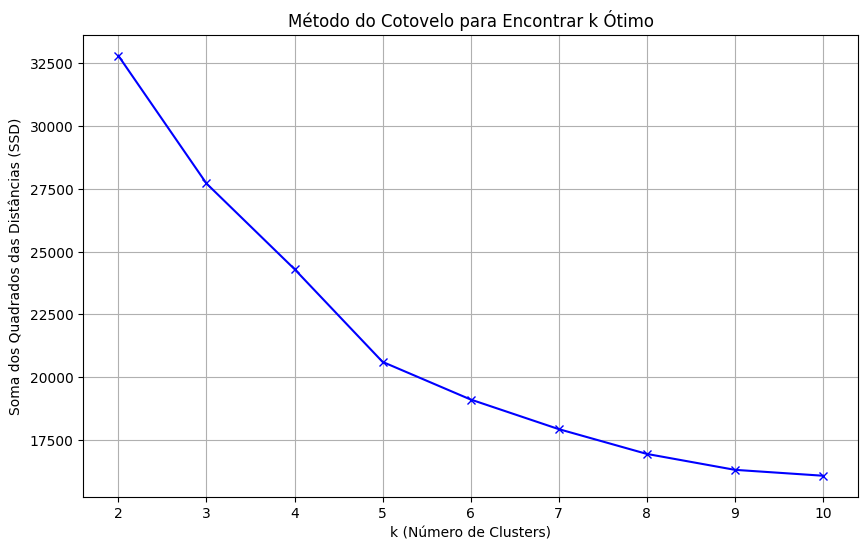

In [232]:
plt.figure(figsize=(10, 6))
plt.plot(k_range, sum_of_squared_distances, 'bx-')
plt.xlabel('k (Número de Clusters)')
plt.ylabel('Soma dos Quadrados das Distâncias (SSD)')
plt.title('Método do Cotovelo para Encontrar k Ótimo')
plt.xticks(k_range)
plt.grid(True)
plt.show()

### Coeficiente de Silhueta (Silhouette Method)

O coeficiente de silhueta mede quão bem um objeto se encaixa em seu próprio cluster (coesão) em comparação com outros clusters (separação). Um valor próximo de 1 indica que o objeto está bem correspondido ao seu próprio cluster e mal correspondido aos clusters vizinhos. Um valor próximo de -1 indica o oposto. Valores próximos de 0 indicam clusters sobrepostos.

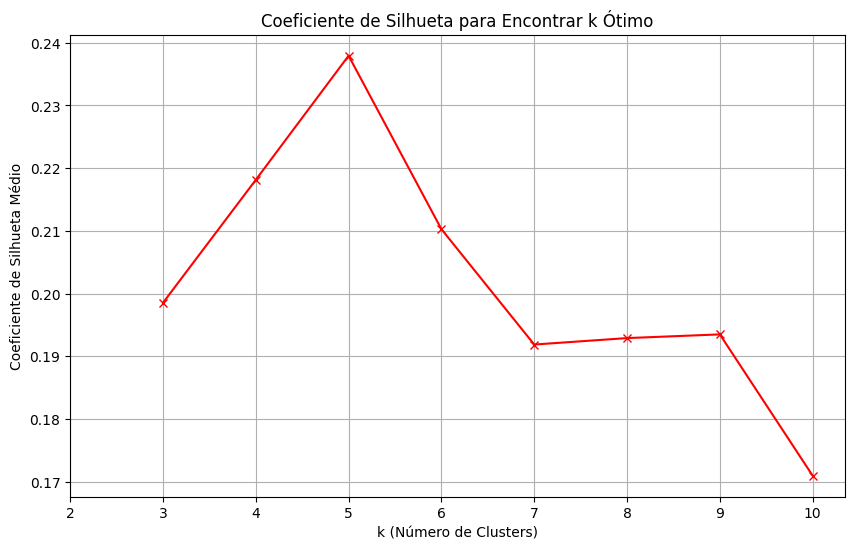

In [233]:
plt.figure(figsize=(10, 6))
plt.plot(k_range[1:], silhouette_scores[1:], 'rx-') # k=1 não tem silhouette score
plt.xlabel('k (Número de Clusters)')
plt.ylabel('Coeficiente de Silhueta Médio')
plt.title('Coeficiente de Silhueta para Encontrar k Ótimo')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Com base nos gráficos acima, você pode analisar e escolher o valor de `k` que melhor se adequa aos seus dados. O método do cotovelo busca o ponto onde a curva se 'dobra' mais acentuadamente, enquanto o coeficiente de silhueta busca o valor mais alto.

## Aplicação do K-Means com k = 5 e Visualização dos Clusters

Com base na análise anterior, vamos aplicar o algoritmo K-Means com `k=5` e visualizar os resultados dos clusters usando os dois primeiros componentes principais.

K-Means com 5 clusters aplicado a X_scaled_encoded. Rótulos de cluster gerados.


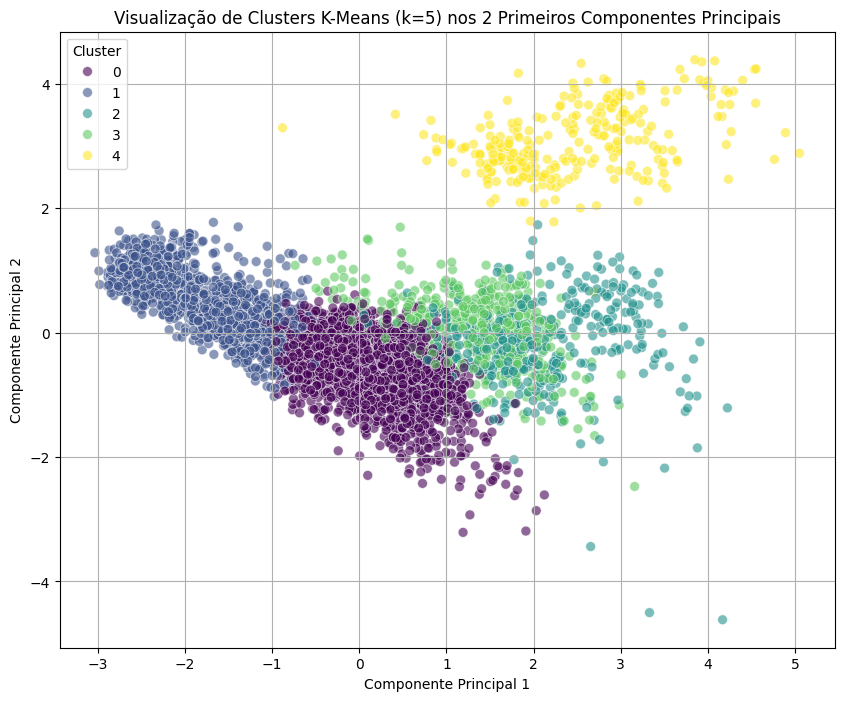

In [234]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Aplicar K-Means com o k escolhido (k=5) nos dados X_scaled_encoded
k_chosen = 5

kmeans_model = KMeans(n_clusters=k_chosen, random_state=42, n_init='auto')
cluster_labels = kmeans_model.fit_predict(X_scaled_encoded)

print(f"K-Means com {k_chosen} clusters aplicado a X_scaled_encoded. Rótulos de cluster gerados.")

# Criar um novo PCA com 2 componentes APENAS para visualização
pca_for_viz = PCA(n_components=2)
X_pca_2d = pca_for_viz.fit_transform(X_scaled_encoded)

# Visualizar os clusters usando os dois primeiros componentes principais do PCA_for_viz
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_pca_2d[:, 0], # Primeiro componente principal para visualização
    y=X_pca_2d[:, 1], # Segundo componente principal para visualização
    hue=cluster_labels, # Cor por rótulo de cluster do K-Means em X_scaled_encoded
    palette='viridis', # Escolha de paleta de cores
    s=50, # Tamanho dos pontos
    alpha=0.6 # Transparência
)
plt.title(f'Visualização de Clusters K-Means (k={k_chosen}) nos 2 Primeiros Componentes Principais')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

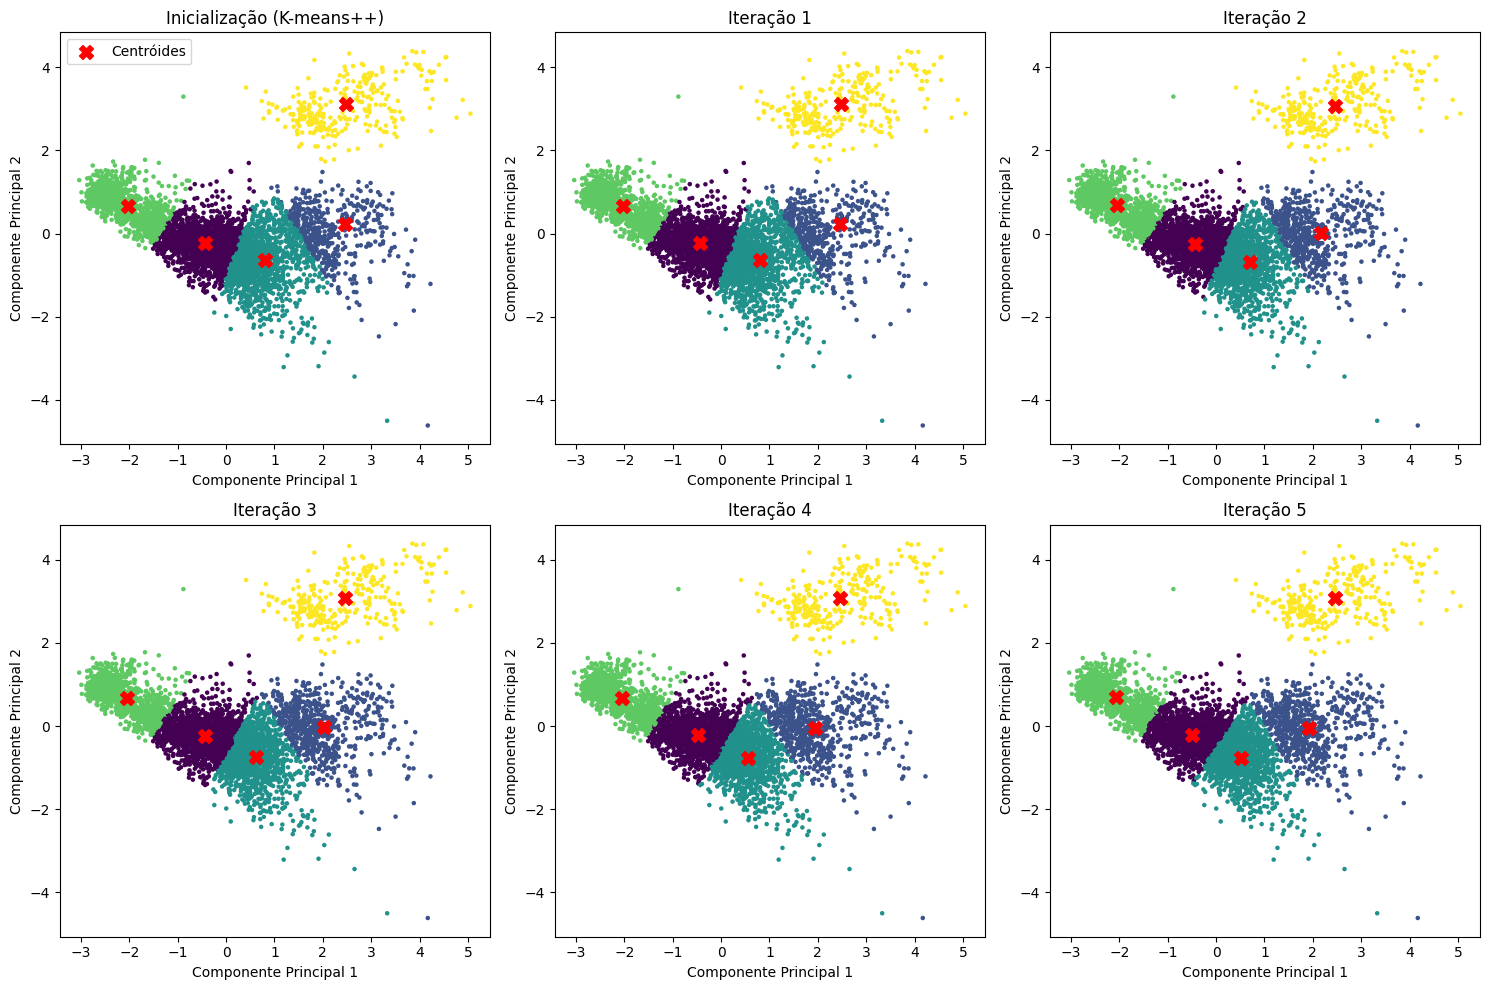

In [235]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

# Usamos X_pca_2d para visualizar os clusters, pois ele já é uma representação 2D
X_display = X_pca_2d
k = k_chosen # Usar o k_chosen atual (que é 3)

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
axs = axs.flatten() # Achata o array de subplots para facilitar a iteração

ax_initial = axs[0]
ax_initial.set_title("Inicialização (K-means++)")
# Para a visualização inicial, podemos rodar o kmeans com 1 iteração e pegar os centros
kmeans_initial = KMeans(n_clusters=k, random_state=42, n_init=1, max_iter=1).fit(X_display)
y_initial = kmeans_initial.labels_
ax_initial.scatter(X_display[:, 0], X_display[:, 1], c=y_initial, s=5, cmap='viridis')
ax_initial.scatter(kmeans_initial.cluster_centers_[:, 0], kmeans_initial.cluster_centers_[:, 1], c="red", marker='X', s=100, label='Centróides')
ax_initial.legend()
ax_initial.set_xlabel('Componente Principal 1')
ax_initial.set_ylabel('Componente Principal 2')


max_it = 5 # Número de iterações para visualizar

for it in range(1, max_it + 1):
    # Rodar K-Means com o número de iterações crescente
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=1, # Para cada subplot, uma nova inicialização é feita (ou poderia ser 'auto' para o melhor resultado)
        max_iter=it,
        init='k-means++' # Explicitamente usando k-means++ para inicialização inteligente
    ).fit(X_display)

    y = kmeans.labels_
    ax = axs[it] # Próximo subplot
    ax.set_title(f'Iteração {it}')
    ax.scatter(X_display[:, 0], X_display[:, 1], c=y, s=5, cmap='viridis')
    ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker='X', s=100)
    ax.set_xlabel('Componente Principal 1')
    ax.set_ylabel('Componente Principal 2')

# Desabilitar eixos para subplots não utilizados, se houver
for i in range(max_it + 1, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

### Análise dos Componentes Principais: O que significam?

In [236]:
import pandas as pd
from sklearn.decomposition import PCA

# Obter os nomes das features após o pré-processamento (escalonamento e one-hot encoding)
feature_names = preprocessor.get_feature_names_out()

# Criar um NOVO PCA com 2 componentes para interpretar os eixos da visualização
pca_interpretation = PCA(n_components=2)
pca_interpretation.fit(X_scaled_encoded)

# Criar um DataFrame para os loadings dos componentes principais
# pca_interpretation.components_ contém os loadings. Cada linha é um componente principal,
# e cada coluna corresponde a uma feature original (após pré-processamento).
loadings_df = pd.DataFrame(
    pca_interpretation.components_,
    columns=feature_names
)

print("Loadings (contribuições das features originais) para os Componentes Principais:")
# Vamos mostrar as contribuições para os dois primeiros componentes principais
display(loadings_df.head(2))

# Para uma análise mais clara, vamos identificar as features com maiores pesos (positivos e negativos)
# para o Componente Principal 1 e Componente Principal 2.

print("\n--- Top 5 Features Positivas e Negativas para o Componente Principal 1 ---")
cp1_loadings = loadings_df.iloc[0].sort_values(ascending=False)
display(pd.concat([cp1_loadings.head(5), cp1_loadings.tail(5)]))

print("\n--- Top 5 Features Positivas e Negativas para o Componente Principal 2 ---")
cp2_loadings = loadings_df.iloc[1].sort_values(ascending=False)
display(pd.concat([cp2_loadings.head(5), cp2_loadings.tail(5)]))

print("\nCom base nesta análise, podemos interpretar que:")
# Interpretação baseada nos loadings do PCA de 2 componentes para visualização
# O Componente Principal 1 (eixo X) é predominantemente influenciado por:
cp1_positive_features = ', '.join(cp1_loadings.head(3).index.str.replace('num__', '').str.replace('cat__', ''))
cp1_negative_features = ', '.join(cp1_loadings.tail(3).index.str.replace('num__', '').str.replace('cat__', ''))
print(f"- O Componente Principal 1 (eixo X) é predominantemente influenciado positivamente por: {cp1_positive_features}. E negativamente por: {cp1_negative_features}.")

# O Componente Principal 2 (eixo Y) é predominantemente influenciado por:
cp2_positive_features = ', '.join(cp2_loadings.head(3).index.str.replace('num__', '').str.replace('cat__', ''))
cp2_negative_features = ', '.join(cp2_loadings.tail(3).index.str.replace('num__', '').str.replace('cat__', ''))
print(f"- O Componente Principal 2 (eixo Y) é predominantemente influenciado positivamente por: {cp2_positive_features}. E negativamente por: {cp2_negative_features}.")

Loadings (contribuições das features originais) para os Componentes Principais:


,num__age,num__hypertension,num__heart_disease,num__avg_glucose_level,num__bmi,cat__gender_Female,cat__gender_Male,cat__ever_married_No,cat__ever_married_Yes,cat__work_type_Govt_job,cat__work_type_Never_worked,cat__work_type_Private,cat__work_type_Self-employed,cat__work_type_children,cat__Residence_type_Rural,cat__Residence_type_Urban,cat__smoking_status_Unknown,cat__smoking_status_formerly smoked,cat__smoking_status_never smoked,cat__smoking_status_smokes
0,0.583288,0.356899,0.286230,0.347692,0.416884,-0.001946,0.001946,-0.221948,0.221948,0.025391,-0.003086,0.058514,0.067234,-0.148053,-0.001842,0.001842,-0.140079,0.059733,0.052748,0.027598
1,-0.078165,0.095240,0.720345,0.325602,-0.525963,-0.102970,0.102970,0.109663,-0.109663,-0.018275,0.001014,-0.102466,0.009457,0.110269,0.000873,-0.000873,0.095188,-0.007477,-0.075193,-0.012519



--- Top 5 Features Positivas e Negativas para o Componente Principal 1 ---


num__age                       0.583288
num__bmi                       0.416884
num__hypertension              0.356899
num__avg_glucose_level         0.347692
num__heart_disease             0.286230
cat__gender_Female            -0.001946
cat__work_type_Never_worked   -0.003086
cat__smoking_status_Unknown   -0.140079
cat__work_type_children       -0.148053
cat__ever_married_No          -0.221948
Name: 0, dtype: float64


--- Top 5 Features Positivas e Negativas para o Componente Principal 2 ---


num__heart_disease         0.720345
num__avg_glucose_level     0.325602
cat__work_type_children    0.110269
cat__ever_married_No       0.109663
cat__gender_Male           0.102970
num__age                  -0.078165
cat__work_type_Private    -0.102466
cat__gender_Female        -0.102970
cat__ever_married_Yes     -0.109663
num__bmi                  -0.525963
Name: 1, dtype: float64


Com base nesta análise, podemos interpretar que:
- O Componente Principal 1 (eixo X) é predominantemente influenciado positivamente por: age, bmi, hypertension. E negativamente por: smoking_status_Unknown, work_type_children, ever_married_No.
- O Componente Principal 2 (eixo Y) é predominantemente influenciado positivamente por: heart_disease, avg_glucose_level, work_type_children. E negativamente por: gender_Female, ever_married_Yes, bmi.


# Modelagem: regressão e classificação do `stroke`

Esta parte aplica ao dataset de AVC:
- **Regressão Linear:** mínimos quadrados, equações normais, resíduos e métricas.
- **Gradiente Descendente & Regularização:** taxa de aprendizado, escalonamento, mini-batch, atributos polinomiais, Ridge, Lasso e Elastic Net.
- **Regressão Logística:** sigmoide, chances, entropia cruzada, gradiente e limiar de decisão.
- **Métricas de Classificação:** matriz de confusão, precisão, revocação, F1/F-beta, acurácia balanceada, MCC, log loss e Brier.

O alvo é `stroke`, que vale 0 ou 1. Uma regressão linear sobre um alvo binário é um **modelo de probabilidade linear**: o valor previsto é uma estimativa da chance de AVC. Esse modelo tem limitações (pode prever valores menores que 0 ou maiores que 1), e elas aparecem nas análises abaixo. A forma adequada de tratar esse alvo é a regressão logística (Parte 3), avaliada com métricas de classificação (Parte 4).

Os tratamentos da APS1 (seções acima) são reaproveitados:
- `Other` em `gender` vira `Female`;
- o `bmi` ausente é preenchido com a mediana;
- as numéricas passam por `StandardScaler` e as categóricas por `OneHotEncoder`;
- a separação treino/teste é estratificada.

In [237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# O 'dataset' já foi carregado na APS1; aqui só conferimos
print("Formato do dataset:", dataset.shape)

Formato do dataset: (5110, 12)


## 0. Preparação

Repetimos os tratamentos da APS1 e separamos treino e teste do mesmo jeito (80/20, estratificado, `random_state=42`).

O **teste fica guardado até o final**. Todas as comparações entre modelos usam validação cruzada no treino: o α nunca é escolhido pelo erro de treino nem pelo de teste.

In [238]:
from sklearn.model_selection import train_test_split, StratifiedKFold

dados = dataset.drop(columns=["id"]).copy()
dados["gender"] = dados["gender"].replace("Other", "Female")

X = dados.drop(columns=["stroke"])
y = dados["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y            # mantém ~5% de AVC em treino e teste
)

num_features = X.select_dtypes(include=["number"]).columns.tolist()
cat_features = X.select_dtypes(include=["object"]).columns.tolist()

# Validação cruzada estratificada em 5 dobras, usada em todas as comparações
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Treino:", X_train.shape, "| % AVC:", round(y_train.mean() * 100, 2))
print("Teste :", X_test.shape, "| % AVC:", round(y_test.mean() * 100, 2))
print("Numéricas:", num_features)
print("Categóricas:", cat_features)

Treino: (4088, 10) | % AVC: 4.87
Teste : (1022, 10) | % AVC: 4.89
Numéricas: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categóricas: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [239]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


def criar_preprocessor():
    # Mesmo pré-processamento da APS1, agora dentro de um Pipeline:
    # mediana e escala aprendem só com o treino de cada dobra (sem vazamento)
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), num_features),
            # drop="first" evita colunas redundantes com o intercepto (XᵀX invertível)
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                                  sparse_output=False), cat_features)
        ])

# Parte 1 — Regressão Linear

## 1.1 Regressão simples feita à mão: `stroke` em função de `age`

Na seção de correlações da APS1, `age` foi a numérica mais correlacionada com `stroke`. Ajustamos ŷ = w₀ + w₁·idade pelas **equações normais** (XᵀX w = Xᵀy), usando `np.linalg.solve` em vez de inverter a matriz.

Depois conferimos duas coisas:
- se a inclinação bate com a fórmula w₁ = r · s_y / s_x;
- se os resíduos satisfazem Σe = 0 e Σe·x = 0.

In [240]:
x_idade = X_train["age"].to_numpy(dtype=float)
y_tr = y_train.to_numpy(dtype=float)

# Matriz de projeto: coluna de 1s (intercepto) + idade
X_simples = np.column_stack([np.ones_like(x_idade), x_idade])

# Equações normais: XᵀX w = Xᵀy
w_simples = np.linalg.solve(X_simples.T @ X_simples, X_simples.T @ y_tr)
print(f"w0 (intercepto) = {w_simples[0]:.5f}")
print(f"w1 (idade)      = {w_simples[1]:.5f}")

# Conferência pela fórmula da regressão simples
r = np.corrcoef(x_idade, y_tr)[0, 1]
print(f"\nr = {r:.4f}  ->  r * s_y / s_x = {r * y_tr.std() / x_idade.std():.5f}")

# Propriedades dos resíduos de mínimos quadrados
residuos_simples = y_tr - X_simples @ w_simples
print(f"\nΣe   = {residuos_simples.sum():.2e}")
print(f"Σe·x = {(residuos_simples * x_idade).sum():.2e}")

w0 (intercepto) = -0.05183
w1 (idade)      = 0.00232

r = 0.2434  ->  r * s_y / s_x = 0.00232

Σe   = -1.78e-14
Σe·x = 2.93e-12


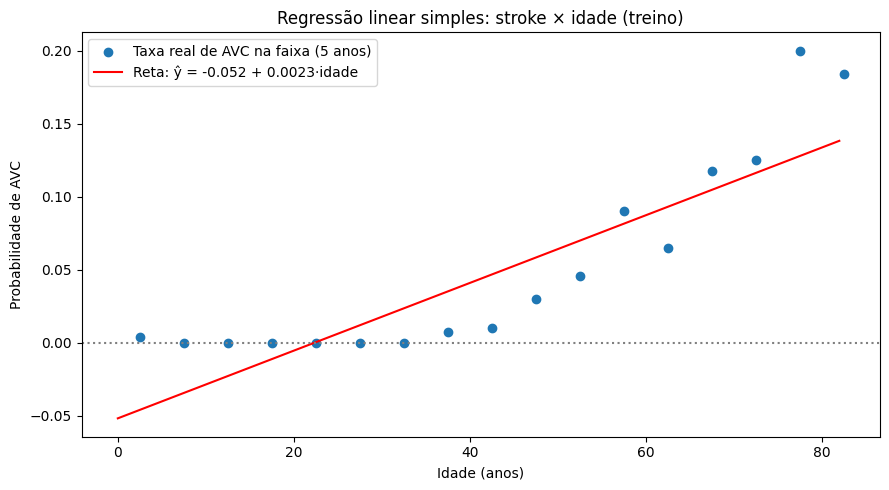

In [241]:
# Como y é 0/1, um scatter puro só mostra duas faixas.
# Comparamos a reta com a taxa real de AVC por faixa de idade.
faixas = pd.cut(X_train["age"], bins=np.arange(0, 90, 5))
taxa_por_faixa = y_train.groupby(faixas, observed=True).mean()
centro_faixas = [intervalo.mid for intervalo in taxa_por_faixa.index]

idades = np.linspace(0, 82, 100)

plt.figure(figsize=(9, 5))
plt.scatter(centro_faixas, taxa_por_faixa.values, label="Taxa real de AVC na faixa (5 anos)")
plt.plot(idades, w_simples[0] + w_simples[1] * idades, "r-",
         label=f"Reta: ŷ = {w_simples[0]:.3f} + {w_simples[1]:.4f}·idade")
plt.axhline(0, color="gray", linestyle=":")
plt.title("Regressão linear simples: stroke × idade (treino)")
plt.xlabel("Idade (anos)")
plt.ylabel("Probabilidade de AVC")
plt.legend()
plt.tight_layout()
plt.show()

**O que observar:**
- A taxa real de AVC cresce de forma **curva** com a idade: fica quase zero até uns 40 anos e depois acelera.
- Uma reta não acompanha esse formato. Ela fica abaixo de zero nas idades baixas (uma "probabilidade" negativa) e subestima o risco nas idades altas.
- Esse é o sintoma de **não linearidade**, que também aparece como curva no gráfico de resíduos. A seção 2.4 tenta corrigi-lo com atributos polinomiais.

## 1.2 Regressão linear múltipla com o pipeline da APS1

Agora usamos todas as variáveis e comparamos sempre com um **`DummyRegressor`**, que prevê a média do treino (a taxa de AVC, ~5%). Um R² negativo significa um modelo pior que esse baseline.

In [242]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate

metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}


def avaliar_cv(modelo, nome):
    # Validação cruzada no treino: média e desvio entre as 5 dobras
    res = cross_validate(modelo, X_train, y_train, cv=cv,
                         scoring=metricas, return_train_score=True)
    return {
        "modelo": nome,
        "RMSE treino": -res["train_RMSE"].mean(),
        "RMSE validação": -res["test_RMSE"].mean(),
        "desvio RMSE (dobras)": res["test_RMSE"].std(),
        "MAE validação": -res["test_MAE"].mean(),
        "R² validação": res["test_R2"].mean(),
    }


dummy = Pipeline([("preprocessor", criar_preprocessor()),
                  ("regressao", DummyRegressor(strategy="mean"))])
ols = Pipeline([("preprocessor", criar_preprocessor()),
                ("regressao", LinearRegression())])

resultados = [avaliar_cv(dummy, "Dummy (média)"),
              avaliar_cv(ols, "Regressão linear (OLS)")]
pd.DataFrame(resultados).set_index("modelo").round(4)

,RMSE treino,RMSE validação,desvio RMSE (dobras),MAE validação,R² validação
modelo,,,,,
Dummy (média),0.2152,0.2152,0.0010,0.0926,-0.0000
Regressão linear (OLS),0.2060,0.2070,0.0015,0.0941,0.0745


**Como ler as métricas:**
- **MAE** é o erro médio absoluto.
- **RMSE** pune mais os erros grandes. Aqui, os erros grandes são os pacientes com AVC que o modelo previu perto de 0.
- **R²** é a fração da variância explicada além da média.

Com um alvo 0/1 e só ~5% de positivos, R² baixo é esperado: a maior parte da variação é ruído individual que as variáveis não explicam.

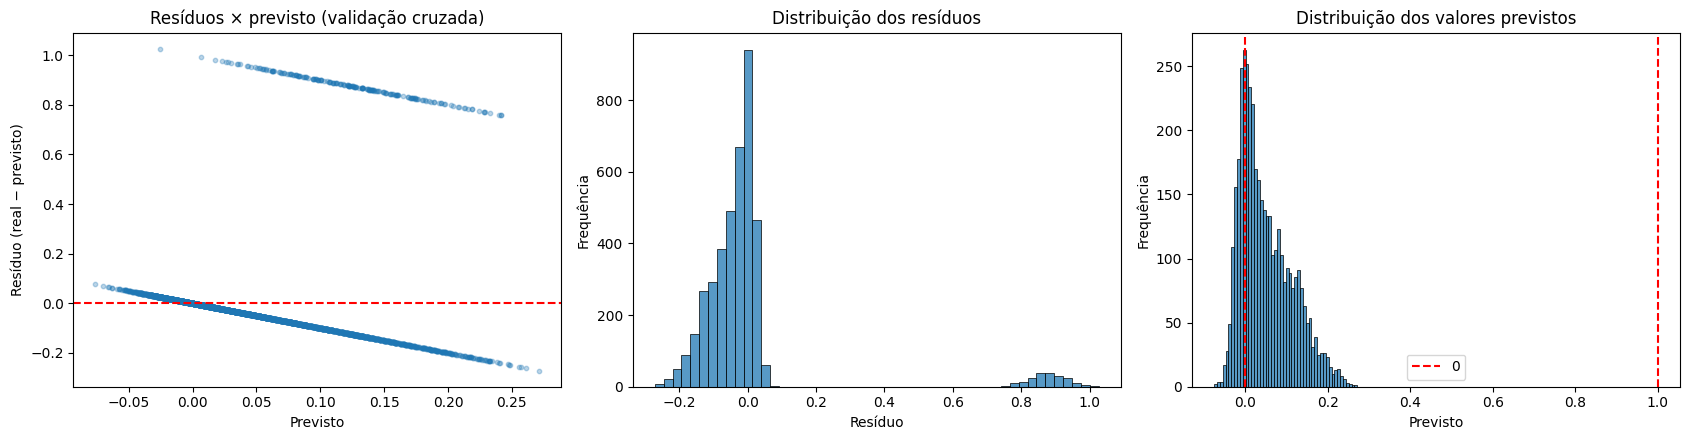

Previsões abaixo de 0: 25.4%
Previsões acima de 1: 0.0%


In [243]:
from sklearn.model_selection import cross_val_predict

# Resíduos "honestos": cada previsão vem de um modelo que não viu aquele paciente
pred_cv = cross_val_predict(ols, X_train, y_train, cv=cv)
residuos_cv = y_train - pred_cv

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(pred_cv, residuos_cv, alpha=0.3, s=10)
axes[0].axhline(0, color="r", linestyle="--")
axes[0].set_title("Resíduos × previsto (validação cruzada)")
axes[0].set_xlabel("Previsto")
axes[0].set_ylabel("Resíduo (real − previsto)")

sns.histplot(residuos_cv, bins=50, ax=axes[1])
axes[1].set_title("Distribuição dos resíduos")
axes[1].set_xlabel("Resíduo")
axes[1].set_ylabel("Frequência")

sns.histplot(pred_cv, bins=50, ax=axes[2])
axes[2].axvline(0, color="r", linestyle="--", label="0")
axes[2].axvline(1, color="r", linestyle="--")
axes[2].set_title("Distribuição dos valores previstos")
axes[2].set_xlabel("Previsto")
axes[2].set_ylabel("Frequência")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Previsões abaixo de 0: {(pred_cv < 0).mean() * 100:.1f}%")
print(f"Previsões acima de 1: {(pred_cv > 1).mean() * 100:.1f}%")

**O que observar (padrões nos resíduos):**
- **Duas faixas diagonais** no gráfico de resíduos: com y sempre 0 ou 1, o resíduo é −ŷ ou 1 − ŷ. Isso quebra a suposição de resíduos com distribuição normal.
- **Funil:** a variância do resíduo de um alvo binário é p(1−p), que muda com p. É **heteroscedasticidade**.
- **Previsões negativas:** confirmam o problema de usar uma reta para uma probabilidade.

Os três pontos indicam que a regressão linear não é o modelo ideal para `stroke`. A regressão logística resolve isso.

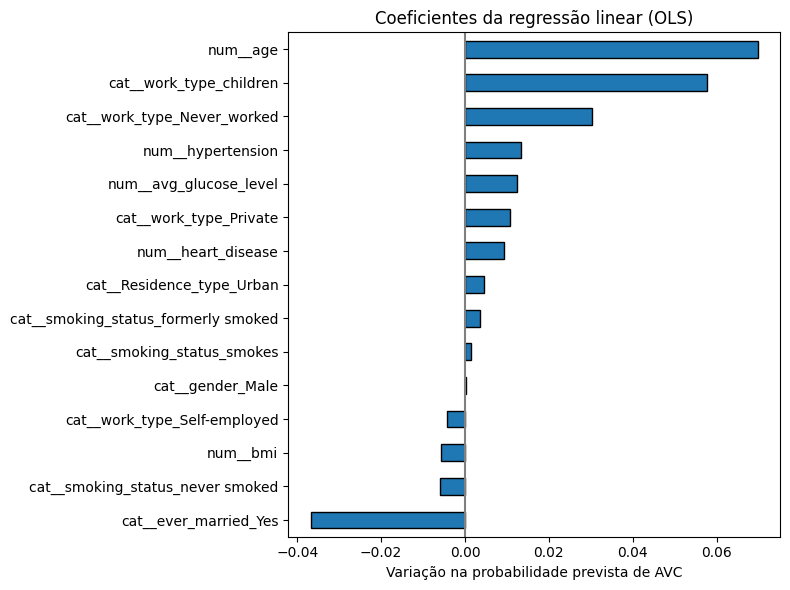

Intercepto: 0.0586


In [244]:
ols.fit(X_train, y_train)
nomes_features = ols.named_steps["preprocessor"].get_feature_names_out()
coef_ols = pd.Series(ols.named_steps["regressao"].coef_, index=nomes_features)

plt.figure(figsize=(8, 6))
coef_ols.sort_values().plot(kind="barh", edgecolor="black")
plt.axvline(0, color="gray")
plt.title("Coeficientes da regressão linear (OLS)")
plt.xlabel("Variação na probabilidade prevista de AVC")
plt.tight_layout()
plt.show()

print("Intercepto:", round(ols.named_steps["regressao"].intercept_, 4))

**Interpretação:**
- O efeito de cada coeficiente vale **mantendo as outras variáveis fixas**.
- Nas numéricas (`num__`), que foram padronizadas, o coeficiente é a variação na probabilidade prevista quando a variável aumenta **1 desvio padrão**. Por isso dá para comparar o tamanho delas.
- Nas categóricas (`cat__`), o coeficiente é a diferença em relação à categoria de referência, a que foi removida pelo `drop="first"`.

# Parte 2 — Gradiente Descendente & Regularização

## 2.1 Gradiente descendente à mão

Em vez da forma fechada, minimizamos J(w) = (1/n)‖y − Xw‖² com a regra w ← w − η·∇J, onde ∇J = −(2/n)Xᵀ(y − Xw). A função `gd` é aplicada à matriz já pré-processada (padronizada).

O **gabarito** é a solução de mínimos quadrados (`np.linalg.lstsq`). Testamos as taxas de aprendizado η ∈ {10⁻³, 10⁻², 10⁻¹}.

RMSE da forma fechada (treino): 0.20612

eta = 0.001   RMSE = 0.20715   maior |w_gd − w_ref| = 0.04629
eta = 0.01    RMSE = 0.20613   maior |w_gd − w_ref| = 0.02755
eta = 0.1     RMSE = 0.20612   maior |w_gd − w_ref| = 0.00934


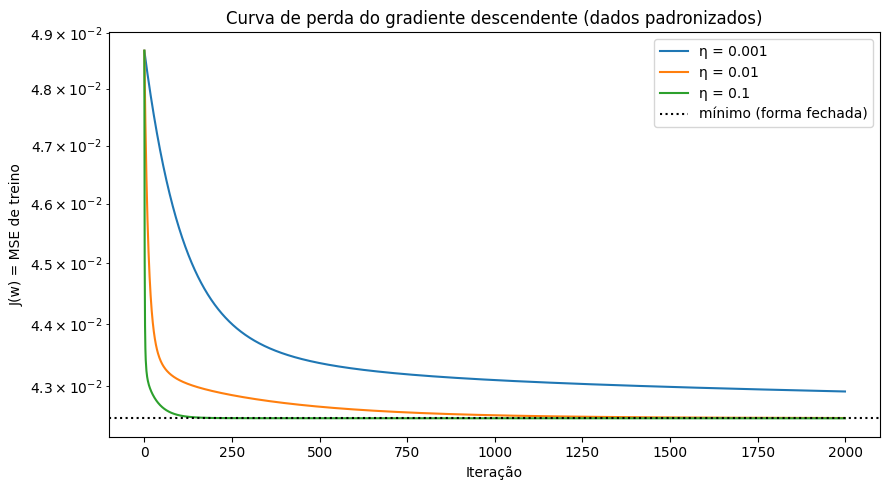

In [245]:
def gd(X, y, eta, iterations):
    n, d = X.shape
    w = np.zeros(d)
    losses = []
    for _ in range(iterations):
        e = y - X @ w
        losses.append(np.mean(e ** 2))
        w = w - eta * (-2 / n) * X.T @ e            # w <- w - eta * gradiente
    return w, np.array(losses)


# Matriz de projeto pré-processada (ajustada só no treino) + coluna de 1s
preprocessor_gd = criar_preprocessor()
Z_train = preprocessor_gd.fit_transform(X_train)
X_std = np.column_stack([np.ones(len(Z_train)), Z_train])

# Gabarito (forma fechada)
w_ref = np.linalg.lstsq(X_std, y_tr, rcond=None)[0]
rmse_ref = np.sqrt(np.mean((y_tr - X_std @ w_ref) ** 2))
print(f"RMSE da forma fechada (treino): {rmse_ref:.5f}\n")

plt.figure(figsize=(9, 5))
for eta in [1e-3, 1e-2, 1e-1]:
    w_gd, losses = gd(X_std, y_tr, eta=eta, iterations=2000)
    rmse_gd = np.sqrt(np.mean((y_tr - X_std @ w_gd) ** 2))
    print(f"eta = {eta:<6}  RMSE = {rmse_gd:.5f}   maior |w_gd − w_ref| = {np.abs(w_gd - w_ref).max():.5f}")
    plt.plot(losses, label=f"η = {eta}")

plt.axhline(rmse_ref ** 2, color="k", linestyle=":", label="mínimo (forma fechada)")
plt.yscale("log")
plt.title("Curva de perda do gradiente descendente (dados padronizados)")
plt.xlabel("Iteração")
plt.ylabel("J(w) = MSE de treino")
plt.legend()
plt.tight_layout()
plt.show()

**O que observar:**
- A curva deve cair de forma suave. Quanto maior o η, mais rápido ela chega ao mínimo.
- Com η = 10⁻³, 2000 iterações não bastam: os pesos ainda ficam longe do gabarito.
- Com η = 10⁻¹, o gradiente descendente chega à mesma solução da forma fechada.

## 2.2 Por que escalonar: o limite da taxa de aprendizado

O gradiente descendente converge apenas se η < 2/λ_max, onde λ_max é a maior curvatura (o maior autovalor de (2/n)XᵀX).

Comparamos as numéricas **cruas** (idade em anos e glicose em mg/dL, com valores na casa das centenas) com as mesmas colunas **padronizadas**.

In [246]:
# Só as numéricas contínuas, com bmi preenchido pela mediana do treino
cols = ["age", "avg_glucose_level", "bmi"]
A = X_train[cols].fillna(X_train[cols].median()).to_numpy(dtype=float)
X_cru = np.column_stack([np.ones(len(A)), A])
X_pad = np.column_stack([np.ones(len(A)), (A - A.mean(axis=0)) / A.std(axis=0)])

for nome, M in [("cru", X_cru), ("padronizado", X_pad)]:
    autovalores = np.linalg.eigvalsh((2 / len(M)) * M.T @ M)
    print(f"{nome:<12} λ_max = {autovalores.max():>12.2f}   limite de η = 2/λ_max = {2 / autovalores.max():.2e}"
          f"   razão λ_max/λ_min = {autovalores.max() / autovalores.min():,.0f}")

# Com η = 0.01 (estável para os padronizados), os dados crus divergem
with np.errstate(over="ignore", invalid="ignore"):
    _, perdas_cru = gd(X_cru, y_tr, eta=0.01, iterations=10)
_, perdas_pad = gd(X_pad, y_tr, eta=0.01, iterations=10)
print("\nJ nas 10 primeiras iterações com η = 0.01")
print("cru        :", np.array2string(perdas_cru, precision=3, max_line_width=200))
print("padronizado:", np.array2string(perdas_pad, precision=3, max_line_width=200))

cru          λ_max =     31901.74   limite de η = 2/λ_max = 6.27e-05   razão λ_max/λ_min = 289,580
padronizado  λ_max =         2.97   limite de η = 2/λ_max = 6.73e-01   razão λ_max/λ_min = 2

J nas 10 primeiras iterações com η = 0.01
cru        : [4.868e-02 3.377e+02 3.414e+07 3.453e+12 3.492e+17 3.532e+22 3.572e+27 3.612e+32 3.653e+37 3.695e+42]
padronizado: [0.049 0.048 0.048 0.048 0.048 0.048 0.047 0.047 0.047 0.047]


**O que observar:**
- Com os dados crus, a glicose (valores na casa das centenas) gera uma curvatura enorme. O limite de η fica minúsculo, e o η = 0,01 faz a perda **explodir**.
- Depois de padronizar, todas as direções têm curvatura parecida (razão próxima de 1). A "tigela" fica redonda, e o mesmo η converge.

Por isso o `StandardScaler` vem antes de qualquer gradiente descendente ou penalidade.

## 2.3 Mini-batch e `SGDRegressor`

Cada passo do gradiente em lote completo custa O(n·d). O **mini-batch** usa só 32 amostras por passo: dá muitos passos por época, mas a curva oscila. O `SGDRegressor` do scikit-learn faz o mesmo laço por dentro.

batch_size = 1     passos = 4088  RMSE final = 0.27907
batch_size = 32    passos = 128   RMSE final = 0.20750
batch_size = 1024  passos = 4     RMSE final = 0.21691


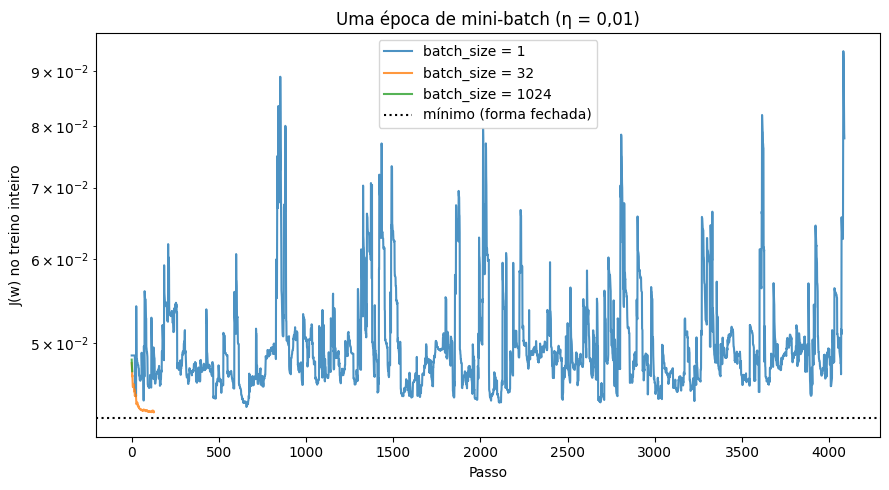

In [247]:
def minibatch_gd(X, y, eta, epochs, batch_size, seed=0):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d)
    losses = []
    for _ in range(epochs):
        order = rng.permutation(n)                  # embaralha a cada época
        for start in range(0, n, batch_size):
            batch = order[start:start + batch_size]
            e = y[batch] - X[batch] @ w
            w = w - eta * (-2 / len(batch)) * X[batch].T @ e
            losses.append(np.mean((y - X @ w) ** 2))   # J no conjunto todo, só para plotar
    return w, np.array(losses)


plt.figure(figsize=(9, 5))
for bs in [1, 32, 1024]:
    w_mb, perdas_mb = minibatch_gd(X_std, y_tr, eta=0.01, epochs=1, batch_size=bs)
    print(f"batch_size = {bs:<5} passos = {len(perdas_mb):<5} RMSE final = {np.sqrt(perdas_mb[-1]):.5f}")
    plt.plot(perdas_mb, label=f"batch_size = {bs}", alpha=0.8)

plt.axhline(rmse_ref ** 2, color="k", linestyle=":", label="mínimo (forma fechada)")
plt.title("Uma época de mini-batch (η = 0,01)")
plt.xlabel("Passo")
plt.ylabel("J(w) no treino inteiro")
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.show()

In [248]:
from sklearn.linear_model import SGDRegressor

sgd = Pipeline([
    ("preprocessor", criar_preprocessor()),
    ("regressao", SGDRegressor(loss="squared_error", penalty="l2", alpha=1e-4,
                               learning_rate="invscaling", max_iter=1000, random_state=42))
])
resultados.append(avaliar_cv(sgd, "SGDRegressor (L2)"))
pd.DataFrame(resultados).set_index("modelo").round(4)

,RMSE treino,RMSE validação,desvio RMSE (dobras),MAE validação,R² validação
modelo,,,,,
Dummy (média),0.2152,0.2152,0.0010,0.0926,-0.0000
Regressão linear (OLS),0.2060,0.2070,0.0015,0.0941,0.0745
SGDRegressor (L2),0.2063,0.2074,0.0017,0.0939,0.0712


## 2.4 Atributos polinomiais: subajuste × sobreajuste

A reta da seção 1.1 não acompanhou a curva da idade. Adicionamos termos de grau 2 e 3 (quadrados e interações) com `PolynomialFeatures` e comparamos o RMSE de **treino** com o de **validação**.

Critério:
- **sobreajuste** é treino baixo com validação alta e instável entre as dobras;
- **subajuste** é os dois altos e próximos.

In [249]:
from sklearn.preprocessing import PolynomialFeatures

for grau in [1, 2, 3]:
    poly = Pipeline([
        ("preprocessor", criar_preprocessor()),
        ("poly", PolynomialFeatures(degree=grau, include_bias=False)),
        ("regressao", LinearRegression())
    ])
    resultados.append(avaliar_cv(poly, f"Polinomial grau {grau} (OLS)"))

tabela = pd.DataFrame(resultados).set_index("modelo")
tabela.loc[[m for m in tabela.index if m.startswith("Polinomial")]].round(4)

,RMSE treino,RMSE validação,desvio RMSE (dobras),MAE validação,R² validação
modelo,,,,,
Polinomial grau 1 (OLS),0.2060,0.2070,0.0015,0.0941,0.0745
Polinomial grau 2 (OLS),0.2005,0.2108,0.0042,0.0941,0.0405
Polinomial grau 3 (OLS),0.1840,0.2635,0.0170,0.1202,-0.5071


**O que observar:**
- Com o grau 3 aparecem centenas de colunas. O RMSE de treino cai, mas o de validação e o **desvio entre as dobras** sobem: é o sobreajuste ("errar de forma imprevisível").
- É aqui que a regularização entra.

## 2.5 Regularização: Ridge, Lasso e Elastic Net

A regularização adiciona uma penalidade aos pesos:
- **Ridge (L2):** J(w) = ‖y − Xw‖² + α Σ wⱼ². "Divide" os pesos e encolhe todos.
- **Lasso (L1):** J(w) = ‖y − Xw‖² + α Σ |wⱼ|. "Subtrai e corta em zero", e assim seleciona variáveis.
- **Elastic Net:** mistura os dois, controlada pelo `l1_ratio`.

O intercepto não é penalizado (o scikit-learn já faz isso). As variáveis precisam estar na mesma escala, por isso o `StandardScaler` vem antes.

### Caminho de regularização

Vemos como cada coeficiente muda à medida que α cresce: o Ridge encolhe todos aos poucos, e o Lasso zera um por um.

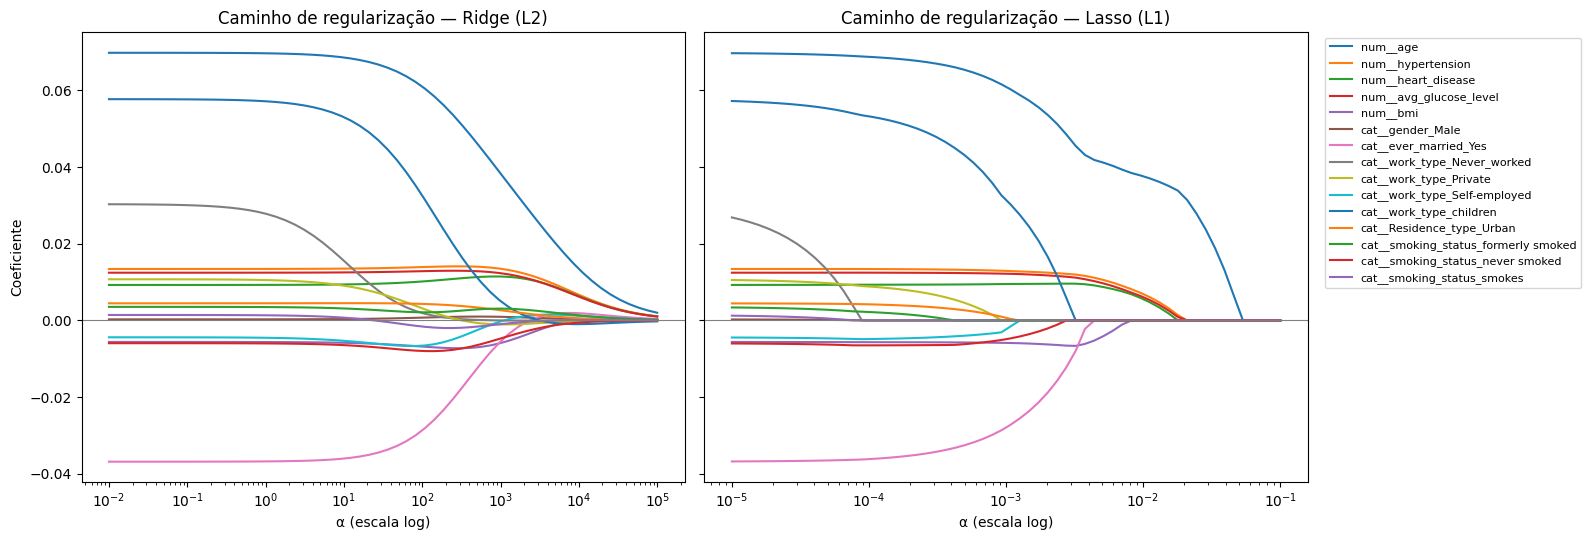

Lasso α = 0.0001  coeficientes não nulos: 13/15
Lasso α = 0.001   coeficientes não nulos: 10/15
Lasso α = 0.005   coeficientes não nulos: 5/15
Lasso α = 0.01    coeficientes não nulos: 4/15


In [250]:
from sklearn.linear_model import Ridge, Lasso

alphas_ridge = np.logspace(-2, 5, 60)
alphas_lasso = np.logspace(-5, -1, 60)

coefs_ridge = np.array([Ridge(alpha=a).fit(Z_train, y_tr).coef_ for a in alphas_ridge])
coefs_lasso = np.array([Lasso(alpha=a, max_iter=10_000).fit(Z_train, y_tr).coef_ for a in alphas_lasso])
nomes = preprocessor_gd.get_feature_names_out()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, alphas, coefs, titulo in [(axes[0], alphas_ridge, coefs_ridge, "Ridge (L2)"),
                                  (axes[1], alphas_lasso, coefs_lasso, "Lasso (L1)")]:
    for j, nome in enumerate(nomes):
        ax.plot(alphas, coefs[:, j], label=nome)
    ax.set_xscale("log")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"Caminho de regularização — {titulo}")
    ax.set_xlabel("α (escala log)")
axes[0].set_ylabel("Coeficiente")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Quantos coeficientes sobrevivem no Lasso
for a in [1e-4, 1e-3, 5e-3, 1e-2]:
    n_nao_nulos = np.sum(Lasso(alpha=a, max_iter=10_000).fit(Z_train, y_tr).coef_ != 0)
    print(f"Lasso α = {a:<7} coeficientes não nulos: {n_nao_nulos}/{len(nomes)}")

### Escolha de α por validação cruzada

O α é escolhido por validação cruzada, **nunca pelo erro de treino** (que sempre prefere α = 0). Usamos `RidgeCV`, `LassoCV` e `ElasticNetCV` dentro do pipeline.

Também aplicamos Ridge sobre os atributos polinomiais de grau 3 para ver se a regularização controla o sobreajuste da seção 2.4.

In [251]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV

modelos_reg = {
    "Ridge (RidgeCV)": RidgeCV(alphas=np.logspace(-3, 5, 50)),
    "Lasso (LassoCV)": LassoCV(cv=cv, max_iter=10_000, random_state=42),
    "Elastic Net (ElasticNetCV)": ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=cv,
                                               max_iter=10_000, random_state=42),
}

for nome, reg in modelos_reg.items():
    pipe = Pipeline([("preprocessor", criar_preprocessor()), ("regressao", reg)])
    resultados.append(avaliar_cv(pipe, nome))
    pipe.fit(X_train, y_train)
    escolhido = pipe.named_steps["regressao"]
    extra = f", l1_ratio = {escolhido.l1_ratio_}" if hasattr(escolhido, "l1_ratio_") else ""
    print(f"{nome:<28} α escolhido = {escolhido.alpha_:.5f}{extra}   "
          f"coeficientes não nulos = {np.sum(escolhido.coef_ != 0)}/{len(escolhido.coef_)}")

poly3_ridge = Pipeline([
    ("preprocessor", criar_preprocessor()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaler", StandardScaler()),            # escala de novo: os termos polinomiais têm escalas diferentes
    ("regressao", RidgeCV(alphas=np.logspace(-1, 5, 50)))
])
resultados.append(avaliar_cv(poly3_ridge, "Polinomial grau 3 + Ridge"))

tabela = pd.DataFrame(resultados).set_index("modelo").sort_values("RMSE validação")
tabela.round(4)

Ridge (RidgeCV)              α escolhido = 37.27594   coeficientes não nulos = 15/15
Lasso (LassoCV)              α escolhido = 0.00040   coeficientes não nulos = 12/15
Elastic Net (ElasticNetCV)   α escolhido = 0.00044, l1_ratio = 0.9   coeficientes não nulos = 12/15


,RMSE treino,RMSE validação,desvio RMSE (dobras),MAE validação,R² validação
modelo,,,,,
Lasso (LassoCV),0.2061,0.2070,0.0014,0.0930,0.0748
Elastic Net (ElasticNetCV),0.2061,0.2070,0.0014,0.0930,0.0748
Polinomial grau 1 (OLS),0.2060,0.2070,0.0015,0.0941,0.0745
Regressão linear (OLS),0.2060,0.2070,0.0015,0.0941,0.0745
Ridge (RidgeCV),0.2061,0.2070,0.0014,0.0931,0.0745
SGDRegressor (L2),0.2063,0.2074,0.0017,0.0939,0.0712
Polinomial grau 3 + Ridge,0.2033,0.2081,0.0013,0.0873,0.0651
Polinomial grau 2 (OLS),0.2005,0.2108,0.0042,0.0941,0.0405
Dummy (média),0.2152,0.2152,0.0010,0.0926,-0.0000


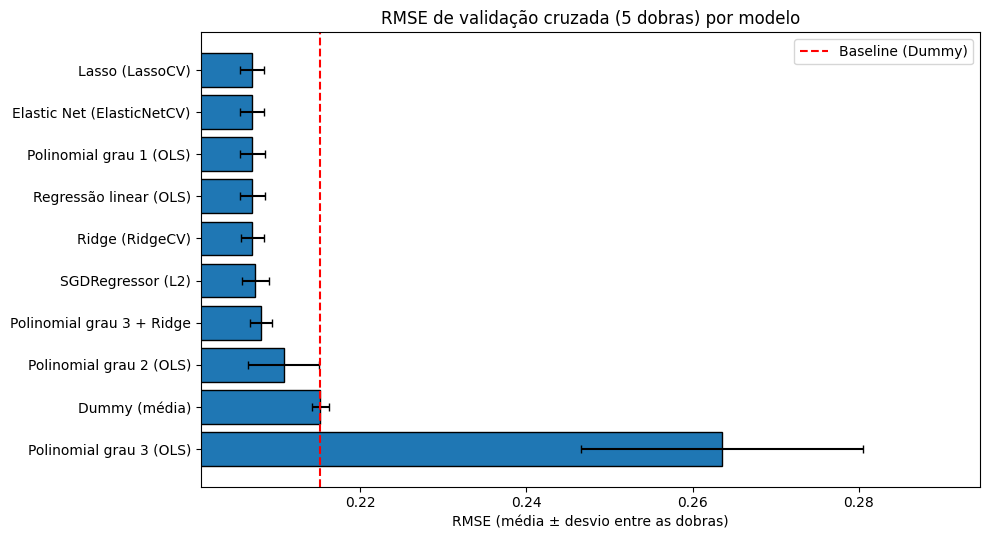

In [252]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(tabela.index, tabela["RMSE validação"], xerr=tabela["desvio RMSE (dobras)"],
        edgecolor="black", capsize=3)
ax.axvline(tabela.loc["Dummy (média)", "RMSE validação"], color="r", linestyle="--",
           label="Baseline (Dummy)")
ax.invert_yaxis()
ax.set_xlim(left=tabela["RMSE validação"].min() * 0.97)
ax.set_title("RMSE de validação cruzada (5 dobras) por modelo")
ax.set_xlabel("RMSE (média ± desvio entre as dobras)")
ax.legend()
plt.tight_layout()
plt.show()

**O que observar:**
- Os modelos lineares, com ou sem regularização, ficam **muito próximos**. Com cerca de 4 mil linhas e só ~16 colunas, quase não há sobreajuste para corrigir. Por isso o Ridge escolhe um α pequeno e o efeito é mínimo.
- A regularização faz mais diferença no polinomial de grau 3, que tem centenas de colunas.
- O Lasso mostra quais variáveis o modelo dispensa: os coeficientes zerados.

## 2.6 Avaliação final no conjunto de teste

Só agora usamos o teste, uma única vez, para comparar o baseline, o OLS e os três regularizados.

In [253]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

finais = {
    "Dummy (média)": dummy,
    "Regressão linear (OLS)": ols,
    **{nome: Pipeline([("preprocessor", criar_preprocessor()), ("regressao", reg)])
       for nome, reg in modelos_reg.items()},
    "Polinomial grau 3 + Ridge": poly3_ridge,
}

linhas = []
for nome, modelo in finais.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    linhas.append({"modelo": nome,
                   "MAE teste": mean_absolute_error(y_test, pred),
                   "RMSE teste": root_mean_squared_error(y_test, pred),
                   "R² teste": r2_score(y_test, pred)})

pd.DataFrame(linhas).set_index("modelo").round(4)

,MAE teste,RMSE teste,R² teste
modelo,,,
Dummy (média),0.0928,0.2157,-0.0000
Regressão linear (OLS),0.0928,0.2056,0.0913
Ridge (RidgeCV),0.0922,0.2057,0.0906
Lasso (LassoCV),0.0923,0.2057,0.0902
Elastic Net (ElasticNetCV),0.0923,0.2057,0.0902
Polinomial grau 3 + Ridge,0.0861,0.2054,0.0930


## Conclusões — Partes 1 e 2

Preencha com os números obtidos ao rodar. Pontos a discutir:

1. **Regressão linear:**
   - A regressão linear supera o Dummy?
   - Quanto do R² vem só da idade (seção 1.1) e quanto das outras variáveis?
2. **Resíduos:**
   - As duas faixas, o funil e as previsões fora de [0, 1] mostram que as suposições da regressão linear não valem para um alvo binário.
3. **Otimização:**
   - Sem padronizar, o gradiente descendente diverge. Depois de padronizar, ele chega à mesma solução da forma fechada.
   - O mini-batch converge em uma época, mas oscila.
4. **Regularização:**
   - Com poucas variáveis, Ridge, Lasso e Elastic Net ficam perto do OLS.
   - A regularização ajuda principalmente quando o modelo tem muitos termos (polinomial).
   - O Lasso indica quais variáveis o modelo dispensa.
5. **Próximo passo:** tratar `stroke` como classificação (Partes 3 e 4). O modelo passa a prever probabilidades entre 0 e 1 e é avaliado com métricas que consideram o desbalanceamento (~5% de AVC).

# Parte 3 — Regressão Logística

## 3.1 Reta × sigmoide

A regressão logística passa o escore linear z = wᵀx + b pela **sigmoide**, σ(z) = 1/(1 + e⁻ᶻ). A saída fica sempre entre 0 e 1 e pode ser lida como probabilidade.

Comparamos com a reta da seção 1.1, usando só a idade. `C=np.inf` desliga a penalidade, para termos o modelo puro.

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


w = 0.0748   b = -7.2410


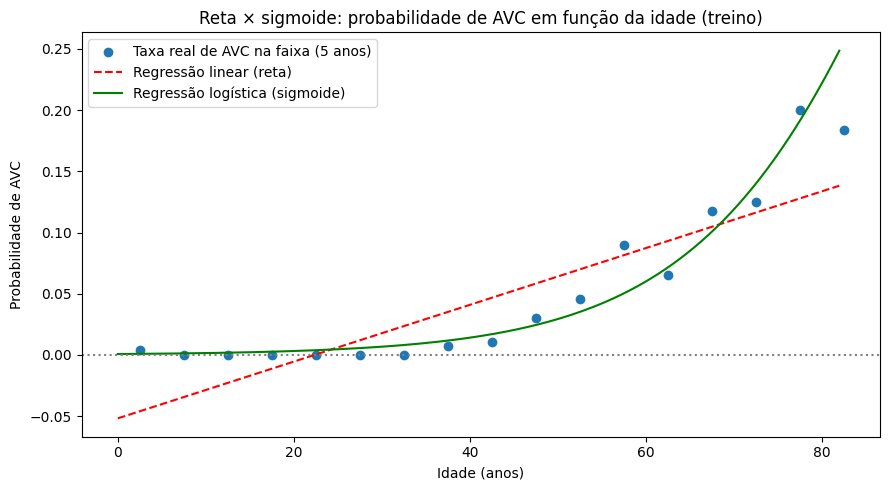

In [254]:
from sklearn.linear_model import LogisticRegression


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


X_idade = X_train[["age"]].to_numpy(dtype=float)
logit_idade = LogisticRegression(C=np.inf, max_iter=1000).fit(X_idade, y_train)
w_log, b_log = logit_idade.coef_[0, 0], logit_idade.intercept_[0]
print(f"w = {w_log:.4f}   b = {b_log:.4f}")

idades = np.linspace(0, 82, 200)

plt.figure(figsize=(9, 5))
plt.scatter(centro_faixas, taxa_por_faixa.values, label="Taxa real de AVC na faixa (5 anos)")
plt.plot(idades, w_simples[0] + w_simples[1] * idades, "r--", label="Regressão linear (reta)")
plt.plot(idades, sigmoid(w_log * idades + b_log), "g-", label="Regressão logística (sigmoide)")
plt.axhline(0, color="gray", linestyle=":")
plt.title("Reta × sigmoide: probabilidade de AVC em função da idade (treino)")
plt.xlabel("Idade (anos)")
plt.ylabel("Probabilidade de AVC")
plt.legend()
plt.tight_layout()
plt.show()

**O que observar:**
- A sigmoide nunca sai de [0, 1].
- Ela acompanha o formato curvo da taxa real: quase zero nos jovens e crescendo de forma acelerada depois dos 50 anos. Esse era justamente o problema da reta na seção 1.1.

## 3.2 Do escore à probabilidade

Conferimos que `predict_proba` é exatamente σ(`decision_function`) e que `predict` corresponde a p̂ ≥ 0,5.

In [255]:
novos = np.array([[30.0], [60.0], [80.0]])          # três pacientes novos (idade)
z = logit_idade.decision_function(novos)             # o escore w*x + b
print("idade        ", novos.ravel())
print("z            ", z.round(3))
print("sigmoid(z)   ", sigmoid(z).round(4))
print("predict_proba", logit_idade.predict_proba(novos)[:, 1].round(4))
print("predict      ", logit_idade.predict(novos))

idade         [30. 60. 80.]
z             [-4.997 -2.752 -1.256]
sigmoid(z)    [0.0067 0.06   0.2217]
predict_proba [0.0067 0.06   0.2217]
predict       [0 0 0]


Repare se, mesmo aos 80 anos, a probabilidade prevista fica abaixo de 0,5. Nesse caso o `predict` devolve 0 para todos: com ~5% de AVC, o limiar padrão de 0,5 quase nunca é atingido. A seção 3.7 e a Parte 4 tratam disso.

## 3.3 Chances (odds) e interpretação do coeficiente

O logito é z = ln(p/(1−p)). Um ano a mais de idade **multiplica a chance** de AVC por e^w. Conferimos que a razão entre as chances de idades vizinhas é constante.

In [256]:
chance = lambda p: p / (1 - p)

print(f"e^w = {np.exp(w_log):.4f}  ->  cada ano a mais multiplica a chance de AVC por {np.exp(w_log):.3f}")
print(f"a cada 10 anos: x {np.exp(10 * w_log):.2f}\n")

p = logit_idade.predict_proba([[50.0], [51.0], [52.0]])[:, 1]
print("p       ", p.round(4))
print("chances ", chance(p).round(4))
print("razões  ", (chance(p)[1:] / chance(p)[:-1]).round(4))

e^w = 1.0777  ->  cada ano a mais multiplica a chance de AVC por 1.078
a cada 10 anos: x 2.11

p        [0.0293 0.0315 0.0339]
chances  [0.0302 0.0325 0.0351]
razões   [1.0777 1.0777]


## 3.4 Entropia cruzada

A perda da regressão logística é a **entropia cruzada**: J = −(1/n)Σ[y·ln p̂ + (1−y)·ln(1−p̂)]. Ela pune muito as previsões confiantes e erradas.

Duas referências para comparar:
- um modelo que sempre diz 0,5 tem J = ln 2 ≈ 0,693;
- o baseline mais justo é prever sempre a taxa de AVC do treino.

In [257]:
from sklearn.metrics import log_loss

p_idade = logit_idade.predict_proba(X_idade)[:, 1]
termos = -(y_tr * np.log(p_idade) + (1 - y_tr) * np.log(1 - p_idade))
print(f"entropia cruzada à mão:  {termos.mean():.4f}")
print(f"log_loss (sklearn):      {log_loss(y_train, p_idade):.4f}")
print(f"sempre 0,5:              {np.log(2):.4f}")
print(f"sempre a taxa do treino: {log_loss(y_train, np.full(len(y_tr), y_tr.mean())):.4f}")

entropia cruzada à mão:  0.1584
log_loss (sklearn):      0.1584
sempre 0,5:              0.6931
sempre a taxa do treino: 0.1946


## 3.5 Gradiente descendente da regressão logística

O gradiente tem o mesmo formato do caso linear: ∇J = (1/n)Xᵀ(p̂ − y). Cada iteração tem quatro etapas: forward, perda, backward e atualização.

Usamos a mesma matriz padronizada da seção 2.1 (todas as variáveis) e comparamos o resultado com o `LogisticRegression` do scikit-learn sem penalidade.

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


perda: início 0.6931 (= ln 2)   fim 0.1551
log loss do sklearn: 0.1551
maior |w_gd − w_sklearn| = 0.6947


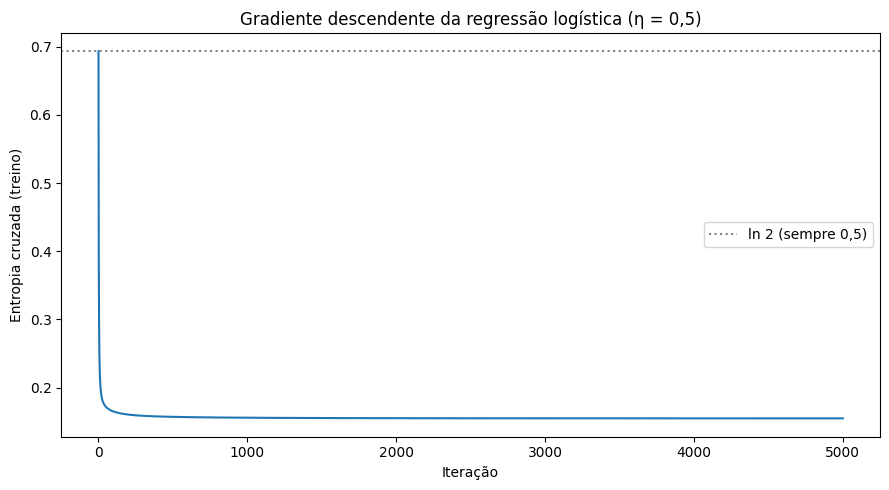

In [258]:
def gd_logistica(X, y, eta, iterations):
    n, d = X.shape
    w = np.zeros(d)
    losses = []
    for _ in range(iterations):
        p = sigmoid(X @ w)                                  # 1. forward
        losses.append(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))   # 2. perda
        grad = X.T @ (p - y) / n                            # 3. backward
        w = w - eta * grad                                  # 4. atualização
    return w, np.array(losses)


# X_std já tem a coluna de 1s (intercepto) e as variáveis pré-processadas
w_glog, perdas_log = gd_logistica(X_std, y_tr, eta=0.5, iterations=5000)

logit_ref = LogisticRegression(C=np.inf, max_iter=5000).fit(Z_train, y_train)
w_sk = np.r_[logit_ref.intercept_, logit_ref.coef_[0]]

print(f"perda: início {perdas_log[0]:.4f} (= ln 2)   fim {perdas_log[-1]:.4f}")
print(f"log loss do sklearn: {log_loss(y_train, logit_ref.predict_proba(Z_train)[:, 1]):.4f}")
print(f"maior |w_gd − w_sklearn| = {np.abs(w_glog - w_sk).max():.4f}")

plt.figure(figsize=(9, 5))
plt.plot(perdas_log)
plt.axhline(np.log(2), color="gray", linestyle=":", label="ln 2 (sempre 0,5)")
plt.title("Gradiente descendente da regressão logística (η = 0,5)")
plt.xlabel("Iteração")
plt.ylabel("Entropia cruzada (treino)")
plt.legend()
plt.tight_layout()
plt.show()

## 3.6 Regressão logística com o pipeline completo

Agora a regressão logística usa o mesmo pré-processamento das partes anteriores. Os coeficientes são lidos como **razões de chances** (e^coef):
- acima de 1, a variável aumenta a chance de AVC;
- abaixo de 1, diminui.

Nas numéricas padronizadas, a razão se refere a +1 desvio padrão.

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


,coef,e^coef (razão de chances)
num__age,1.678,5.356
cat__work_type_children,0.336,1.400
cat__smoking_status_smokes,0.250,1.284
num__avg_glucose_level,0.177,1.194
num__hypertension,0.137,1.147
cat__smoking_status_formerly smoked,0.130,1.139
cat__Residence_type_Urban,0.084,1.088
cat__gender_Male,0.064,1.066
cat__work_type_Private,0.053,1.054
num__heart_disease,0.046,1.047


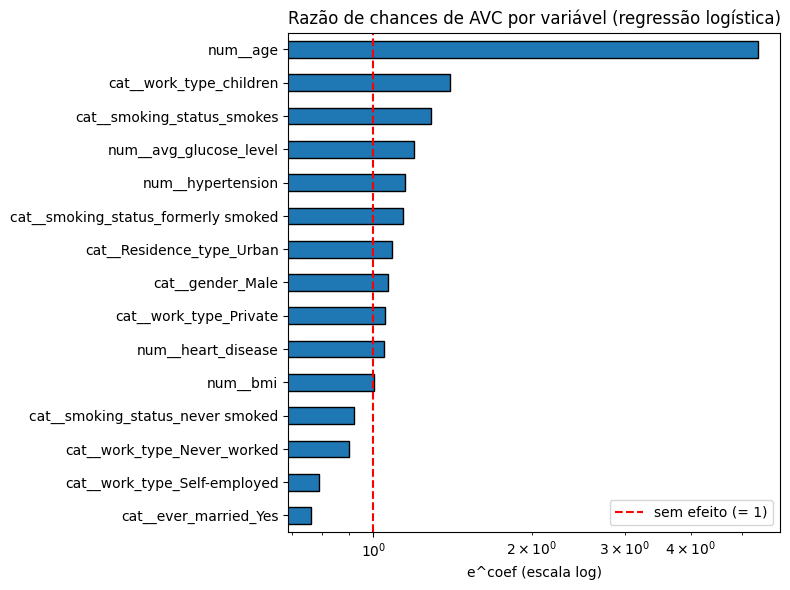

In [259]:
logistica = Pipeline([
    ("preprocessor", criar_preprocessor()),
    ("classificador", LogisticRegression(C=np.inf, max_iter=1000))
])
logistica.fit(X_train, y_train)

nomes_log = logistica.named_steps["preprocessor"].get_feature_names_out()
coef_log = pd.Series(logistica.named_steps["classificador"].coef_[0], index=nomes_log)
razoes = pd.DataFrame({"coef": coef_log, "e^coef (razão de chances)": np.exp(coef_log)})
display(razoes.sort_values("coef", ascending=False).round(3))

plt.figure(figsize=(8, 6))
np.exp(coef_log).sort_values().plot(kind="barh", edgecolor="black")
plt.axvline(1, color="r", linestyle="--", label="sem efeito (= 1)")
plt.xscale("log")
plt.title("Razão de chances de AVC por variável (regressão logística)")
plt.xlabel("e^coef (escala log)")
plt.legend()
plt.tight_layout()
plt.show()

## 3.7 Limiar de decisão

O `predict` usa p̂ ≥ 0,5, mas esse corte é uma **escolha**. Com ~5% de AVC, quase nenhum paciente passa de 0,5.

Para ver o efeito de baixar o limiar, usamos probabilidades **fora da dobra** (`cross_val_predict`): cada paciente do treino recebe uma probabilidade de um modelo que não o viu. O teste continua guardado.

In [260]:
proba_oof = cross_val_predict(logistica, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

for t in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred = (proba_oof >= t).astype(int)
    print(f"limiar {t:<4}: AVC previsto {pred.sum():4d} vezes · AVC perdido {((pred == 0) & (y_tr == 1)).sum():3d}"
          f" de {int(y_tr.sum())} · alarmes falsos {((pred == 1) & (y_tr == 0)).sum():4d}"
          f" · acurácia {np.mean(pred == y_tr):.3f}")

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserW

limiar 0.5 : AVC previsto    1 vezes · AVC perdido 199 de 199 · alarmes falsos    1 · acurácia 0.951
limiar 0.3 : AVC previsto   54 vezes · AVC perdido 186 de 199 · alarmes falsos   41 · acurácia 0.944
limiar 0.2 : AVC previsto  208 vezes · AVC perdido 154 de 199 · alarmes falsos  163 · acurácia 0.922
limiar 0.1 : AVC previsto  687 vezes · AVC perdido  83 de 199 · alarmes falsos  571 · acurácia 0.840
limiar 0.05: AVC previsto 1192 vezes · AVC perdido  42 de 199 · alarmes falsos 1035 · acurácia 0.737


**O que observar:**
- Com o limiar 0,5, a acurácia é alta, mas o modelo **não encontra quase nenhum AVC**.
- Baixando o limiar, o modelo encontra mais AVCs em troca de mais alarmes falsos, e a acurácia cai.
- A acurácia sozinha engana. Por isso a Parte 4 usa métricas que olham para os dois tipos de erro.

## 3.8 Fronteira curva: atributos polinomiais

Como na seção 2.4, testamos se termos de grau 2 melhoram a regressão logística. A comparação usa a entropia cruzada fora da dobra (menor é melhor). A padronização é refeita depois da expansão polinomial.

In [261]:
logistica_poly = Pipeline([
    ("preprocessor", criar_preprocessor()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("classificador", LogisticRegression(C=np.inf, max_iter=5000))
])

for nome, modelo in [("Logística (grau 1)", logistica), ("Logística (grau 2)", logistica_poly)]:
    res = cross_validate(modelo, X_train, y_train, cv=cv, scoring="neg_log_loss", return_train_score=True)
    print(f"{nome:<20} log loss treino {-res['train_score'].mean():.4f}   "
          f"validação {-res['test_score'].mean():.4f} ± {res['test_score'].std():.4f}")

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserW

Logística (grau 1)   log loss treino 0.1547   validação 0.1582 ± 0.0030


C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserW

Logística (grau 2)   log loss treino 0.1367   validação 0.1849 ± 0.0153


Se o log loss de treino cair mas o de validação subir, o modelo de grau 2 está sobreajustando, e o modelo linear (grau 1) é preferível.

# Parte 4 — Métricas de Classificação

O problema é de saúde: **deixar de detectar um AVC (falso negativo) custa mais caro** do que um alarme falso (falso positivo), que só leva a exames adicionais. Essa assimetria orienta a escolha da métrica.

Toda escolha (incluindo o limiar) é feita com as probabilidades fora da dobra do treino. O teste é usado uma única vez, no final.

## 4.1 Matriz de confusão e o paradoxo da acurácia

A matriz é montada com `labels=[1, 0]`, para que o positivo (AVC) apareça primeiro: [[TP, FN], [FP, TN]].

TP=0  FN=199  FP=1  TN=3888


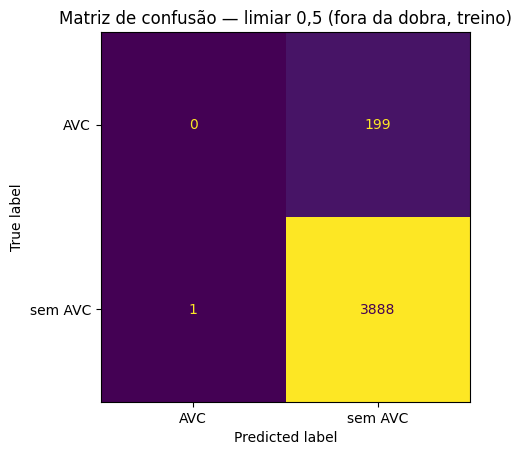

In [262]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef, classification_report)

pred_05 = (proba_oof >= 0.5).astype(int)
cm = confusion_matrix(y_train, pred_05, labels=[1, 0])
tp, fn, fp, tn = cm.ravel()
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

ConfusionMatrixDisplay.from_predictions(y_train, pred_05, labels=[1, 0],
                                        display_labels=["AVC", "sem AVC"], colorbar=False)
plt.title("Matriz de confusão — limiar 0,5 (fora da dobra, treino)")
plt.show()

## 4.2 Métricas à mão × scikit-learn

Cada métrica responde a uma pergunta sobre uma linha ou coluna da matriz:
- **Precisão** = TP/(TP+FP): dos alertas de AVC, quantos eram AVC?
- **Revocação** = TP/(TP+FN): dos AVCs reais, quantos o modelo encontrou?
- **Especificidade** = TN/(TN+FP): dos pacientes sem AVC, quantos foram reconhecidos?
- **F1** = 2PR/(P+R): média harmônica de precisão e revocação.

In [263]:
def calcular_scores(y_true, y_pred):
    return {"acurácia":       accuracy_score(y_true, y_pred),
            "precisão":       precision_score(y_true, y_pred, zero_division=0),
            "revocação":      recall_score(y_true, y_pred),
            "especificidade": recall_score(y_true, y_pred, pos_label=0),
            "F1":             f1_score(y_true, y_pred),
            "F2":             fbeta_score(y_true, y_pred, beta=2),
            "acur. balanceada": balanced_accuracy_score(y_true, y_pred),
            "MCC":            matthews_corrcoef(y_true, y_pred)}


# Um limiar mais baixo para a conta à mão ter TP > 0
pred_02 = (proba_oof >= 0.2).astype(int)
tp, fn, fp, tn = confusion_matrix(y_train, pred_02, labels=[1, 0]).ravel()
a_mao = {"acurácia":       (tp + tn) / (tp + tn + fp + fn),
         "precisão":       tp / (tp + fp),
         "revocação":      tp / (tp + fn),
         "especificidade": tn / (tn + fp),
         "F1":             2 * tp / (2 * tp + fp + fn)}
biblioteca = calcular_scores(y_train, pred_02)
print(f"limiar 0,2: TP={tp} FN={fn} FP={fp} TN={tn}\n")
for nome in a_mao:
    print(f"{nome:<15} à mão {a_mao[nome]:.4f}   sklearn {biblioteca[nome]:.4f}")

limiar 0,2: TP=45 FN=154 FP=163 TN=3726

acurácia        à mão 0.9225   sklearn 0.9225
precisão        à mão 0.2163   sklearn 0.2163
revocação       à mão 0.2261   sklearn 0.2261
especificidade  à mão 0.9581   sklearn 0.9581
F1              à mão 0.2211   sklearn 0.2211


## 4.3 Comparação com baselines

Comparamos três modelos fora da dobra:
- um Dummy que sempre diz "sem AVC";
- um Dummy que sorteia respeitando a proporção de AVC;
- a regressão logística, com o limiar padrão de 0,5 e com um limiar mais baixo (0,1).

A **acurácia balanceada** e o **MCC** não se deixam enganar pelo desbalanceamento: um modelo constante tira 0,5 e 0, respectivamente.

In [264]:
from sklearn.dummy import DummyClassifier

placar = {
    "Dummy (sempre sem AVC)": cross_val_predict(DummyClassifier(strategy="most_frequent"),
                                                X_train, y_train, cv=cv),
    "Dummy (estratificado)":  cross_val_predict(DummyClassifier(strategy="stratified", random_state=0),
                                                X_train, y_train, cv=cv),
    "Logística (limiar 0,5)": (proba_oof >= 0.5).astype(int),
    "Logística (limiar 0,1)": (proba_oof >= 0.1).astype(int),
}
pd.DataFrame({nome: calcular_scores(y_train, pred) for nome, pred in placar.items()}).T.round(3)

,acurácia,precisão,revocação,especificidade,F1,F2,acur. balanceada,MCC
Dummy (sempre sem AVC),0.951,0.000,0.000,1.000,0.000,0.000,0.500,0.000
Dummy (estratificado),0.895,0.058,0.075,0.937,0.065,0.071,0.506,0.011
"Logística (limiar 0,5)",0.951,0.000,0.000,1.000,0.000,0.000,0.500,-0.004
"Logística (limiar 0,1)",0.840,0.169,0.583,0.853,0.262,0.391,0.718,0.251


**O que observar:**
- O Dummy que sempre diz "sem AVC" tem **acurácia de ~95%** e revocação zero. É o paradoxo da acurácia: em dados desbalanceados ela não serve como métrica principal.
- A logística com limiar 0,5 fica perto desse Dummy.
- Com o limiar 0,1, a revocação, o F2, a acurácia balanceada e o MCC sobem, mesmo com a acurácia caindo.

## 4.4 Escolha do limiar

A métrica escolhida é o **F2**, um F-beta com β = 2 que dá à revocação um peso maior que à precisão. Isso reflete o custo maior de não detectar um AVC.

Varremos os limiares e escolhemos o que maximiza o F2 nas probabilidades fora da dobra. Para comparar, também testamos `class_weight="balanced"`, que muda os pesos das classes no treino em vez de mudar o limiar.

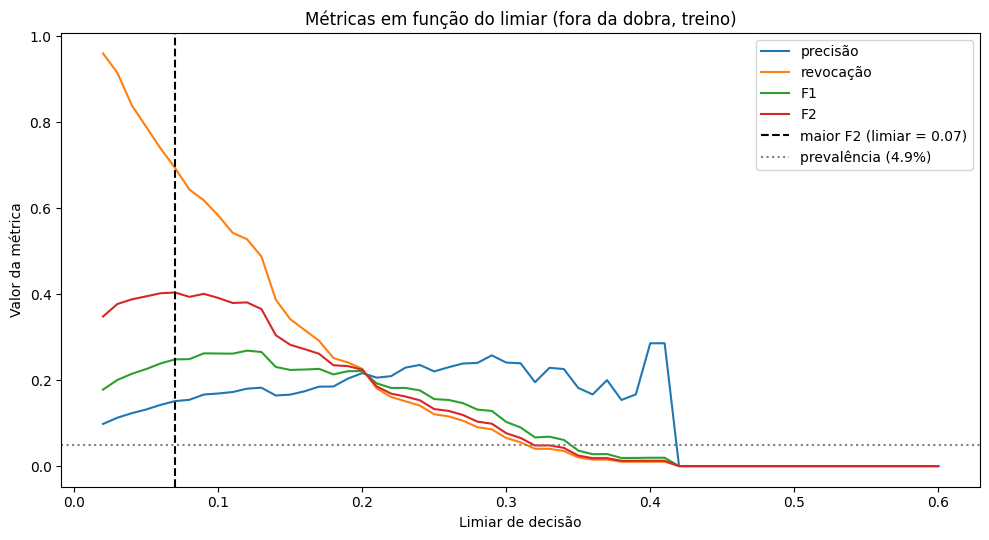

limiar escolhido: 0.07
precisão     0.151
revocação    0.693
F1           0.248
F2           0.404


In [265]:
limiares = np.arange(0.02, 0.61, 0.01)
curvas = pd.DataFrame([{
    "limiar": t,
    "precisão": precision_score(y_train, (proba_oof >= t).astype(int), zero_division=0),
    "revocação": recall_score(y_train, (proba_oof >= t).astype(int)),
    "F1": f1_score(y_train, (proba_oof >= t).astype(int)),
    "F2": fbeta_score(y_train, (proba_oof >= t).astype(int), beta=2),
} for t in limiares]).set_index("limiar")

melhor_limiar = curvas["F2"].idxmax()

plt.figure(figsize=(10, 5.5))
for col in curvas.columns:
    plt.plot(curvas.index, curvas[col], label=col)
plt.axvline(melhor_limiar, color="k", linestyle="--", label=f"maior F2 (limiar = {melhor_limiar:.2f})")
plt.axhline(y_tr.mean(), color="gray", linestyle=":", label=f"prevalência ({y_tr.mean():.1%})")
plt.title("Métricas em função do limiar (fora da dobra, treino)")
plt.xlabel("Limiar de decisão")
plt.ylabel("Valor da métrica")
plt.legend()
plt.tight_layout()
plt.show()

print(f"limiar escolhido: {melhor_limiar:.2f}")
print(curvas.loc[melhor_limiar].round(3).to_string())

In [266]:
logistica_bal = Pipeline([
    ("preprocessor", criar_preprocessor()),
    ("classificador", LogisticRegression(C=np.inf, max_iter=1000, class_weight="balanced"))
])
proba_bal = cross_val_predict(logistica_bal, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

comparacao = {
    f"Logística, limiar {melhor_limiar:.2f}": (proba_oof >= melhor_limiar).astype(int),
    "Logística balanced, limiar 0,5":         (proba_bal >= 0.5).astype(int),
}
pd.DataFrame({nome: calcular_scores(y_train, pred) for nome, pred in comparacao.items()}).T.round(3)

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserW

,acurácia,precisão,revocação,especificidade,F1,F2,acur. balanceada,MCC
"Logística, limiar 0.07",0.795,0.151,0.693,0.801,0.248,0.404,0.747,0.255
"Logística balanced, limiar 0,5",0.739,0.133,0.789,0.737,0.228,0.397,0.763,0.250


**O que observar:**
- A precisão fica baixa em qualquer limiar. Com prevalência de ~5%, até um bom modelo gera muitos alarmes falsos para cada AVC encontrado. Por isso a precisão deve sempre ser reportada **junto com a prevalência**.
- `class_weight="balanced"` com limiar 0,5 e a logística comum com limiar baixo produzem efeitos parecidos: as duas trocam alarmes falsos por AVCs encontrados.

## 4.5 Qualidade das probabilidades: log loss, Brier e calibração

O log loss e o score de Brier, (1/n)Σ(p̂ − y)², avaliam as **probabilidades**, não os rótulos (menor é melhor). A curva de calibração mostra se, entre os pacientes com p̂ ≈ 0,2, cerca de 20% realmente tiveram AVC.

O `class_weight="balanced"` costuma piorar a calibração, porque infla as probabilidades.

Dummy (prevalência)    log loss 0.1946   Brier 0.0463
Logística              log loss 0.1582   Brier 0.0429
Logística balanced     log loss 0.5126   Brier 0.1726


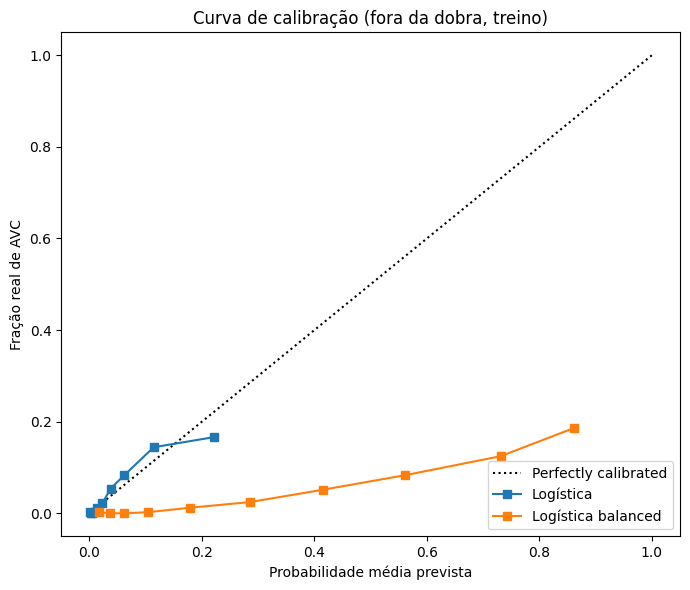

In [267]:
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibrationDisplay

proba_prior = np.full(len(y_tr), y_tr.mean())          # Dummy: sempre a prevalência
for nome, p in [("Dummy (prevalência)", proba_prior),
                ("Logística", proba_oof),
                ("Logística balanced", proba_bal)]:
    print(f"{nome:<22} log loss {log_loss(y_train, p):.4f}   Brier {brier_score_loss(y_train, p):.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(y_train, proba_oof, n_bins=10, strategy="quantile",
                                    name="Logística", ax=ax)
CalibrationDisplay.from_predictions(y_train, proba_bal, n_bins=10, strategy="quantile",
                                    name="Logística balanced", ax=ax)
ax.set_title("Curva de calibração (fora da dobra, treino)")
ax.set_xlabel("Probabilidade média prevista")
ax.set_ylabel("Fração real de AVC")
plt.tight_layout()
plt.show()

## 4.6 Avaliação da logística no conjunto de teste (referência)

A regressão logística com o limiar escolhido em 4.4 é treinada em todo o treino e avaliada no teste. Esta avaliação serve só de referência: nenhuma escolha de modelo, hiperparâmetro ou limiar usa o teste. A avaliação oficial do melhor modelo está na Parte 6.

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


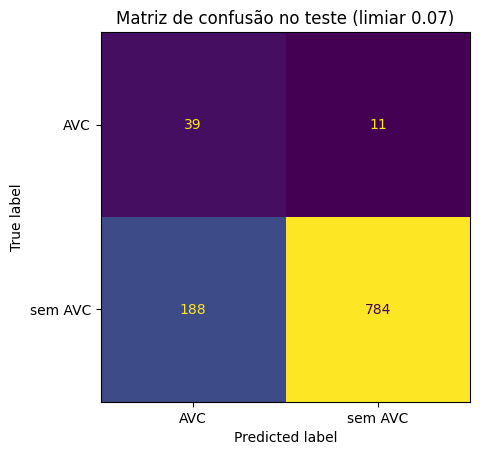

TP=39  FN=11 (AVCs não detectados)  FP=188 (alarmes falsos)  TN=784

              precision    recall  f1-score   support

     sem AVC      0.986     0.807     0.887       972
         AVC      0.172     0.780     0.282        50

    accuracy                          0.805      1022
   macro avg      0.579     0.793     0.584      1022
weighted avg      0.946     0.805     0.858      1022

prevalência no teste: 4.9%


,teste
acurácia,0.805
precisão,0.172
revocação,0.780
especificidade,0.807
F1,0.282
F2,0.457
acur. balanceada,0.793
MCC,0.304
log loss,0.154
Brier,0.041


In [268]:
logistica.fit(X_train, y_train)
proba_teste = logistica.predict_proba(X_test)[:, 1]
pred_teste = (proba_teste >= melhor_limiar).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, pred_teste, labels=[1, 0],
                                        display_labels=["AVC", "sem AVC"], colorbar=False)
plt.title(f"Matriz de confusão no teste (limiar {melhor_limiar:.2f})")
plt.show()

tp, fn, fp, tn = confusion_matrix(y_test, pred_teste, labels=[1, 0]).ravel()
print(f"TP={tp}  FN={fn} (AVCs não detectados)  FP={fp} (alarmes falsos)  TN={tn}\n")
print(classification_report(y_test, pred_teste, target_names=["sem AVC", "AVC"], digits=3))

finais_clf = calcular_scores(y_test, pred_teste)
finais_clf["log loss"] = log_loss(y_test, proba_teste)
finais_clf["Brier"] = brier_score_loss(y_test, proba_teste)
print(f"prevalência no teste: {y_test.mean():.1%}")
pd.Series(finais_clf).round(3).to_frame("teste")

## Conclusões — Partes 3 e 4

Preencha com os números obtidos ao rodar. Pontos a discutir:

1. **Regressão logística:**
   - A sigmoide resolve as previsões fora de [0, 1] da regressão linear e acompanha o formato curvo do risco por idade.
   - Os coeficientes viram razões de chances (ex.: quanto cada ano de idade multiplica a chance de AVC).
2. **Limiar:**
   - Com ~5% de AVC, o limiar 0,5 praticamente não detecta casos.
   - O limiar foi escolhido pelo F2 fora da dobra, para priorizar a revocação.
3. **Métricas:**
   - A acurácia engana (o Dummy tem ~95%).
   - Revocação, F2, acurácia balanceada e MCC mostram o ganho real sobre o baseline.
   - A precisão baixa é consequência da prevalência baixa.
4. **Probabilidades:**
   - Log loss, Brier e a curva de calibração mostram se as probabilidades podem ser usadas como risco.
   - O `class_weight="balanced"` troca calibração por revocação.

# Parte 5 — Seleção e implementação dos modelos

## 5.0 Métrica de desempenho

A métrica única para comparar os modelos é a **average precision (AP)**, que é a área sob a curva precisão-revocação. A escolha tem três motivos:
- **Classe rara:** com ~5% de AVC, a acurácia é inútil (seção 4.3). A ROC-AUC também pode parecer otimista, porque a taxa de falsos positivos é dividida por um número enorme de negativos (Saito & Rehmsmeier, 2015).
- **Foco no AVC:** a AP olha só para a classe positiva. Ela resume, em todos os limiares, quantos AVCs são encontrados (revocação) e quantos alertas são verdadeiros (precisão).
- **Independe de limiar:** os modelos são comparados antes de escolher o corte. O limiar é escolhido depois, pelo F2 (seção 4.4).

O baseline da AP é a prevalência: um modelo sem informação tem AP ≈ 0,05. A ROC-AUC também é reportada, por ser exigida na avaliação final.

Toda a seleção usa a mesma validação: `StratifiedKFold` com 5 dobras (`cv`), aplicada só no treino.

In [269]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

METRICA = "average_precision"
print(f"Prevalência de AVC no treino (AP de um modelo sem informação): {y_train.mean():.4f}")

Prevalência de AVC no treino (AP de um modelo sem informação): 0.0487


## 5.1 Três modelos com o pipeline da APS1

Os três modelos usam o mesmo pré-processamento (`criar_preprocessor`): mediana no `bmi`, `StandardScaler` e `OneHotEncoder`.
- **Dummy:** sempre prevê a prevalência. É o piso de desempenho.
- **Linear com regularização:** regressão logística com penalidade L2 e `C=1` (o padrão do scikit-learn). É rápida, interpretável e um baseline forte.
- **Ensemble de árvores:** Random Forest com 300 árvores (Breiman, 2001). Captura não linearidades e interações sem precisar criá-las à mão. Por exemplo, a curva de risco por idade que a reta não acompanhava na seção 1.1.

Nesta etapa os modelos ainda estão sem ajuste de hiperparâmetros.

,AP treino,AP validação,desvio AP,ROC-AUC validação
modelo,,,,
Dummy (prevalência),0.0487,0.0487,0.0005,0.5000
Logística L2 (C=1),0.1957,0.1925,0.0412,0.8398
Random Forest (padrão),1.0000,0.1727,0.0366,0.8134


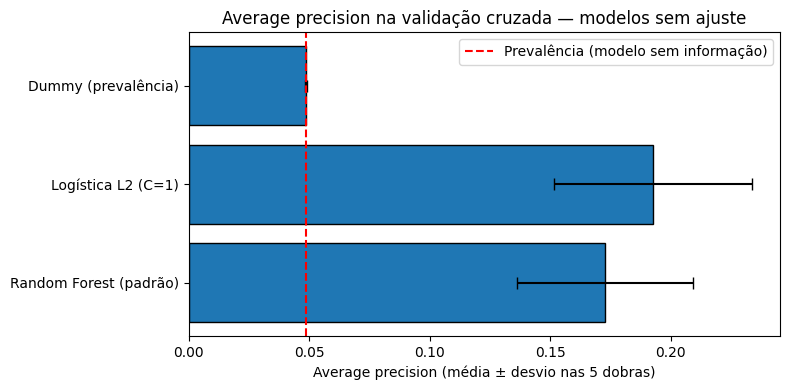

In [270]:
modelos_base = {
    "Dummy (prevalência)": Pipeline([
        ("preprocessor", criar_preprocessor()),
        ("classificador", DummyClassifier(strategy="prior"))]),
    "Logística L2 (C=1)": Pipeline([
        ("preprocessor", criar_preprocessor()),
        ("classificador", LogisticRegression(max_iter=1000))]),
    "Random Forest (padrão)": Pipeline([
        ("preprocessor", criar_preprocessor()),
        ("classificador", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))]),
}

linhas_base, folds_base = [], {}
for nome, modelo in modelos_base.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv, return_train_score=True,
                         scoring={"AP": METRICA, "ROC-AUC": "roc_auc"})
    folds_base[nome] = res["test_AP"]
    linhas_base.append({"modelo": nome,
                        "AP treino": res["train_AP"].mean(),
                        "AP validação": res["test_AP"].mean(),
                        "desvio AP": res["test_AP"].std(),
                        "ROC-AUC validação": res["test_ROC-AUC"].mean()})

tabela_base = pd.DataFrame(linhas_base).set_index("modelo")
display(tabela_base.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tabela_base.index, tabela_base["AP validação"], xerr=tabela_base["desvio AP"],
        edgecolor="black", capsize=4)
ax.axvline(y_train.mean(), color="r", linestyle="--", label="Prevalência (modelo sem informação)")
ax.invert_yaxis()
ax.set_title("Average precision na validação cruzada — modelos sem ajuste")
ax.set_xlabel("Average precision (média ± desvio nas 5 dobras)")
ax.legend()
plt.tight_layout()
plt.show()

**O que observar:**
- **Dummy:** AP igual à prevalência e ROC-AUC 0,5, como esperado.
- **Random Forest sem ajuste:** AP de treino perto de 1 e validação muito mais baixa. Com `min_samples_leaf=1`, cada árvore decora o treino, e com tão poucos AVCs isso vira **sobreajuste**. Por isso a busca de hiperparâmetros a seguir é necessária.

## 5.2 Busca de hiperparâmetros — logística regularizada (`GridSearchCV`)

A grade é pequena (44 combinações), então dá para testar todas. Os hiperparâmetros buscados:
- **`C`** (inverso da força da regularização), em escala log de 10⁻³ a 10². `C` menor significa mais regularização.
- **`penalty`:** L1 (Lasso, pode zerar coeficientes) ou L2 (Ridge, encolhe todos).
- **`class_weight`:** `None` ou `"balanced"`, que dá mais peso aos AVCs no treino.

O solver `liblinear` aceita as duas penalidades.

C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\adrie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Melhores hiperparâmetros: {'classificador__C': np.float64(100.0), 'classificador__class_weight': 'balanced', 'classificador__penalty': 'l1'}
AP validação: 0.1934


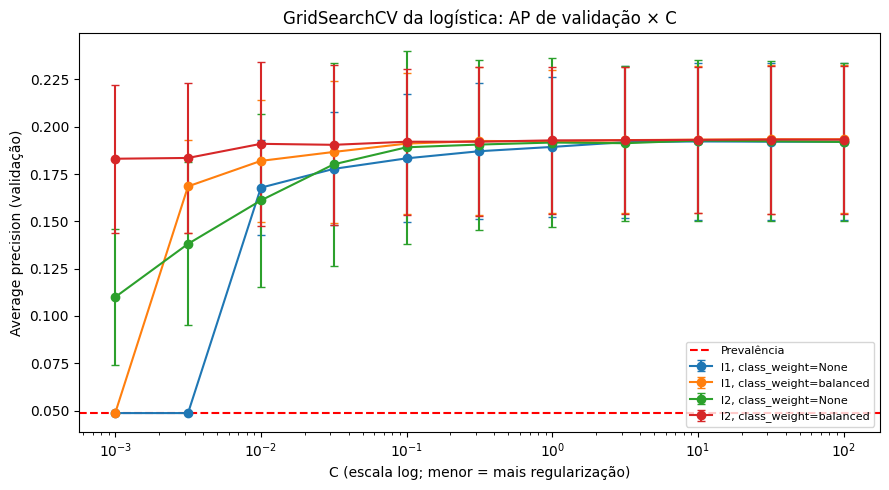

In [271]:
def criar_busca_logistica(preprocessor):
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classificador", LogisticRegression(solver="liblinear", max_iter=2000))])
    grade = {"classificador__C": np.logspace(-3, 2, 11),
             "classificador__penalty": ["l1", "l2"],
             "classificador__class_weight": [None, "balanced"]}
    return GridSearchCV(pipe, grade, scoring=METRICA, cv=cv, n_jobs=-1, return_train_score=True)


busca_log = criar_busca_logistica(criar_preprocessor())
busca_log.fit(X_train, y_train)
print("Melhores hiperparâmetros:", busca_log.best_params_)
print(f"AP validação: {busca_log.best_score_:.4f}")

# Curva de validação: AP em função de C, para cada combinação de penalidade e peso
res_log = pd.DataFrame(busca_log.cv_results_)
res_log["config"] = (res_log["param_classificador__penalty"].astype(str) + ", class_weight="
                     + res_log["param_classificador__class_weight"].astype(str))

plt.figure(figsize=(9, 5))
for config, grupo in res_log.groupby("config"):
    plt.errorbar(grupo["param_classificador__C"].astype(float), grupo["mean_test_score"],
                 yerr=grupo["std_test_score"], marker="o", capsize=3, label=config)
plt.xscale("log")
plt.axhline(y_train.mean(), color="r", linestyle="--", label="Prevalência")
plt.title("GridSearchCV da logística: AP de validação × C")
plt.xlabel("C (escala log; menor = mais regularização)")
plt.ylabel("Average precision (validação)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

**O que observar:**
- Com `C` muito pequeno, a penalidade zera ou encolhe demais os coeficientes, e o modelo perde informação (**subajuste**).
- A partir de certo ponto, a curva fica plana: menos regularização não ajuda, porque o modelo tem poucas variáveis e não sobreajusta.
- Se as curvas de L1 e L2 empatarem, o modelo mais simples (L1, com menos coeficientes) é preferível.

## 5.3 Busca de hiperparâmetros — Random Forest (`RandomizedSearchCV`)

A grade completa teria 240 combinações, então sorteamos 30 com `RandomizedSearchCV`. A busca aleatória costuma achar configurações tão boas quanto a grade completa com muito menos ajustes (Bergstra & Bengio, 2012). Os hiperparâmetros:
- **`min_samples_leaf`** e **`max_depth`** limitam o tamanho das árvores. São os principais freios contra o sobreajuste visto em 5.1.
- **`max_features`** controla quantas variáveis cada divisão sorteia. Menos variáveis deixam as árvores mais diferentes entre si (descorrelação).
- **`class_weight`:** `None` ou `"balanced_subsample"` (pesos recalculados em cada amostra bootstrap).
- **`n_estimators`:** mais árvores nunca pioram o resultado, só custam mais tempo.

Melhores hiperparâmetros: {'classificador__n_estimators': 200, 'classificador__min_samples_leaf': 10, 'classificador__max_features': 0.5, 'classificador__max_depth': None, 'classificador__class_weight': None}
AP validação: 0.2144


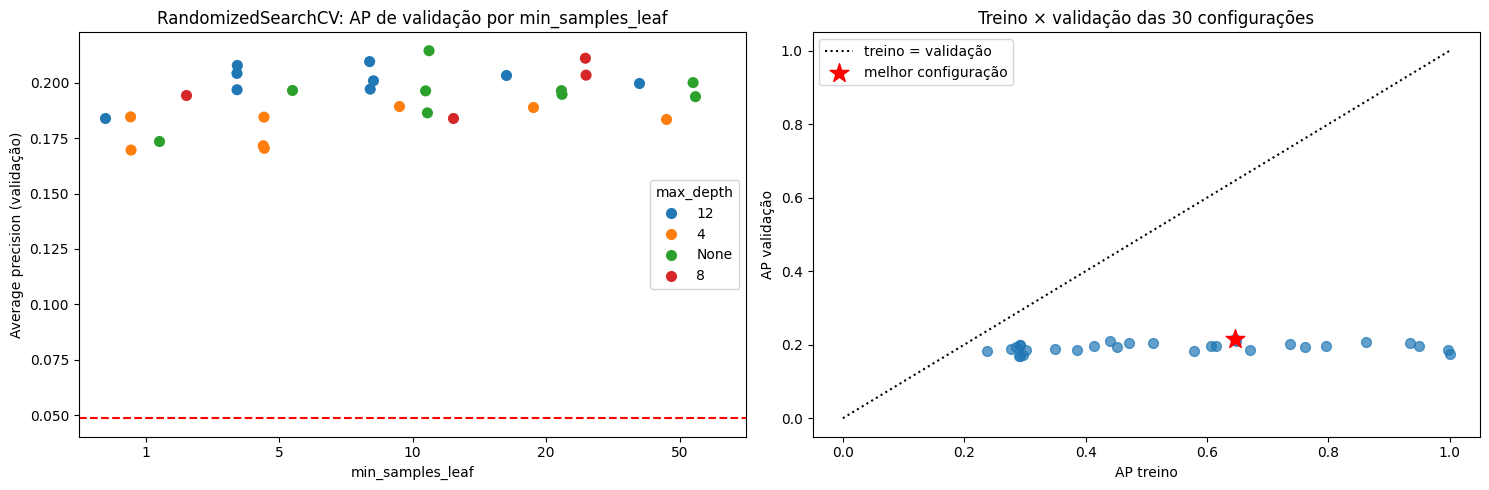

In [272]:
def criar_busca_rf(preprocessor):
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classificador", RandomForestClassifier(random_state=42))])
    distribuicoes = {"classificador__n_estimators": [200, 400],
                     "classificador__max_features": ["sqrt", 0.3, 0.5],
                     "classificador__min_samples_leaf": [1, 5, 10, 20, 50],
                     "classificador__max_depth": [None, 4, 8, 12],
                     "classificador__class_weight": [None, "balanced_subsample"]}
    return RandomizedSearchCV(pipe, distribuicoes, n_iter=30, scoring=METRICA, cv=cv,
                              random_state=42, n_jobs=-1, return_train_score=True)


busca_rf = criar_busca_rf(criar_preprocessor())
busca_rf.fit(X_train, y_train)
print("Melhores hiperparâmetros:", busca_rf.best_params_)
print(f"AP validação: {busca_rf.best_score_:.4f}")

res_rf = pd.DataFrame(busca_rf.cv_results_)
# Texto, para que max_depth=None também apareça na legenda
res_rf["max_depth"] = res_rf["param_classificador__max_depth"].astype(str)
res_rf["min_samples_leaf"] = res_rf["param_classificador__min_samples_leaf"].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.stripplot(data=res_rf, x="min_samples_leaf", y="mean_test_score",
              hue="max_depth", dodge=True, size=8, ax=axes[0])
axes[0].axhline(y_train.mean(), color="r", linestyle="--")
axes[0].set_title("RandomizedSearchCV: AP de validação por min_samples_leaf")
axes[0].set_xlabel("min_samples_leaf")
axes[0].set_ylabel("Average precision (validação)")
axes[0].legend(title="max_depth")

axes[1].scatter(res_rf["mean_train_score"], res_rf["mean_test_score"], s=50, alpha=0.7)
axes[1].plot([0, 1], [0, 1], "k:", label="treino = validação")
melhor = res_rf.loc[busca_rf.best_index_]
axes[1].scatter(melhor["mean_train_score"], melhor["mean_test_score"], s=200, marker="*",
                color="r", label="melhor configuração")
axes[1].set_title("Treino × validação das 30 configurações")
axes[1].set_xlabel("AP treino")
axes[1].set_ylabel("AP validação")
axes[1].legend()
plt.tight_layout()
plt.show()

**O que observar:**
- No gráfico da direita, os pontos com AP de treino perto de 1 (árvores profundas, folhas pequenas) têm validação baixa: é o sobreajuste.
- As melhores configurações costumam ter folhas maiores ou profundidade limitada. Elas trocam um pouco de ajuste ao treino por estabilidade em dados novos.

## 5.4 Comparação dos três modelos após o ajuste

Os três modelos são comparados com a mesma métrica e as mesmas dobras. Usamos a AP de cada dobra da melhor configuração, para comparar dobra a dobra.

,AP validação,desvio AP
Dummy (prevalência),0.0487,0.0005
Logística regularizada,0.1934,0.0392
Random Forest,0.2144,0.0482


Melhor modelo até aqui: Random Forest (AP 0.2144)


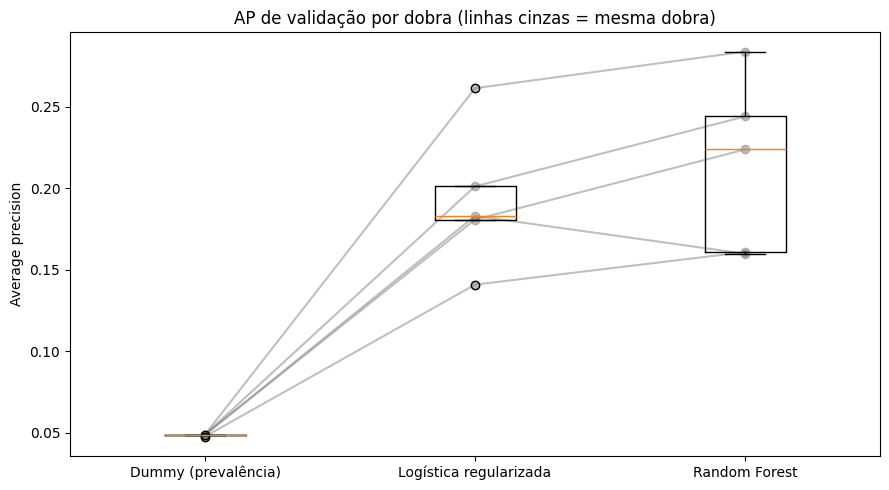

In [273]:
def folds_da_busca(busca):
    # AP de validação em cada dobra, para a melhor configuração da busca
    i = busca.best_index_
    return np.array([busca.cv_results_[f"split{k}_test_score"][i] for k in range(cv.get_n_splits())])


buscas = {"Logística regularizada": busca_log, "Random Forest": busca_rf}
criadores_busca = {"Logística regularizada": criar_busca_logistica, "Random Forest": criar_busca_rf}

folds_ajustados = {"Dummy (prevalência)": folds_base["Dummy (prevalência)"],
                   **{nome: folds_da_busca(b) for nome, b in buscas.items()}}
tabela_ajustada = pd.DataFrame({nome: {"AP validação": f.mean(), "desvio AP": f.std()}
                                for nome, f in folds_ajustados.items()}).T
display(tabela_ajustada.round(4))

melhor_familia = max(buscas, key=lambda nome: buscas[nome].best_score_)
print(f"Melhor modelo até aqui: {melhor_familia} (AP {buscas[melhor_familia].best_score_:.4f})")

plt.figure(figsize=(9, 5))
for k in range(cv.get_n_splits()):
    plt.plot(list(folds_ajustados), [f[k] for f in folds_ajustados.values()],
             "o-", color="gray", alpha=0.5)
plt.boxplot(list(folds_ajustados.values()), positions=range(len(folds_ajustados)), widths=0.3)
plt.xticks(range(len(folds_ajustados)), list(folds_ajustados))
plt.title("AP de validação por dobra (linhas cinzas = mesma dobra)")
plt.ylabel("Average precision")
plt.tight_layout()
plt.show()

## 5.5 Mudança no pipeline

**Proposta:** duas alterações no pré-processamento das numéricas.
1. **Indicador de `bmi` ausente (`MissingIndicator`).** Na APS1, o `bmi` ausente foi preenchido com a mediana, o que apaga a informação de que ele estava faltando. Se a ausência não for aleatória (por exemplo, pacientes internados em estado grave sem medição), ela própria carrega sinal de risco. A célula abaixo verifica isso no treino.
2. **`log1p` em `avg_glucose_level` e `bmi` (`FunctionTransformer`).** A glicose tem distribuição bimodal e assimétrica à direita (histogramas da APS1). O log reduz o peso dos valores extremos nos modelos lineares. Nas árvores, transformações monotônicas não mudam nada, então para a Random Forest só o indicador pode fazer diferença.

In [274]:
# Justificativa: a taxa de AVC muda quando o bmi está ausente?
bmi_ausente = X_train["bmi"].isnull()
print(y_train.groupby(bmi_ausente.rename("bmi ausente")).agg(["mean", "size"])
      .rename(columns={"mean": "taxa de AVC", "size": "pacientes"}).round(4))

             taxa de AVC  pacientes
bmi ausente                        
False             0.0413       3918
True              0.2176        170


Random Forest
  pipeline APS1:       AP 0.2144 ± 0.0482   {'classificador__n_estimators': 200, 'classificador__min_samples_leaf': 10, 'classificador__max_features': 0.5, 'classificador__max_depth': None, 'classificador__class_weight': None}
  pipeline modificado: AP 0.2631 ± 0.0606   {'classificador__n_estimators': 200, 'classificador__min_samples_leaf': 1, 'classificador__max_features': 'sqrt', 'classificador__max_depth': 4, 'classificador__class_weight': None}
  diferença média por dobra: +0.0486  (a mudança melhorou 5 de 5 dobras)


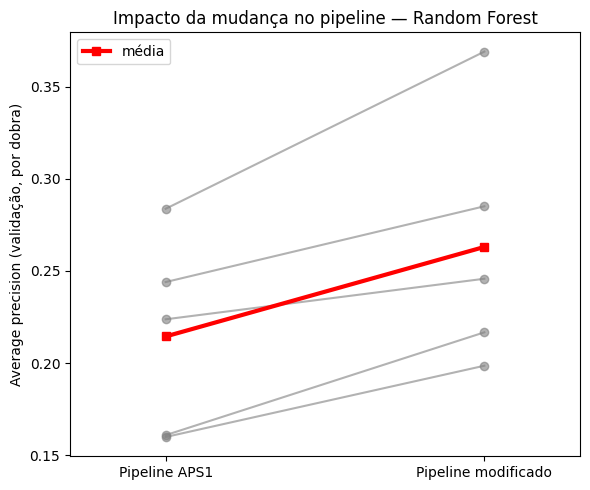


Melhor modelo final: Random Forest (pipeline modificado)


In [275]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import MissingIndicator


def criar_preprocessor_v2():
    # Pipeline da APS1 + indicador de bmi ausente + log nas numéricas assimétricas
    return ColumnTransformer(
        transformers=[
            ("num_log", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scaler", StandardScaler())
            ]), ["avg_glucose_level", "bmi"]),
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), ["age", "hypertension", "heart_disease"]),
            ("bmi_ausente", MissingIndicator(), ["bmi"]),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore",
                                  sparse_output=False), cat_features)
        ])


# Nova busca de hiperparâmetros para o melhor modelo, com o pipeline modificado
busca_v2 = criadores_busca[melhor_familia](criar_preprocessor_v2())
busca_v2.fit(X_train, y_train)
busca_v1 = buscas[melhor_familia]

folds_v1, folds_v2 = folds_da_busca(busca_v1), folds_da_busca(busca_v2)
print(f"{melhor_familia}")
print(f"  pipeline APS1:       AP {folds_v1.mean():.4f} ± {folds_v1.std():.4f}   {busca_v1.best_params_}")
print(f"  pipeline modificado: AP {folds_v2.mean():.4f} ± {folds_v2.std():.4f}   {busca_v2.best_params_}")
print(f"  diferença média por dobra: {np.mean(folds_v2 - folds_v1):+.4f}  "
      f"(a mudança melhorou {np.sum(folds_v2 > folds_v1)} de {len(folds_v1)} dobras)")

plt.figure(figsize=(6, 5))
for k in range(len(folds_v1)):
    plt.plot([0, 1], [folds_v1[k], folds_v2[k]], "o-", color="gray", alpha=0.6)
plt.plot([0, 1], [folds_v1.mean(), folds_v2.mean()], "s-", color="r", lw=3, label="média")
plt.xticks([0, 1], ["Pipeline APS1", "Pipeline modificado"])
plt.xlim(-0.3, 1.3)
plt.title(f"Impacto da mudança no pipeline — {melhor_familia}")
plt.ylabel("Average precision (validação, por dobra)")
plt.legend()
plt.tight_layout()
plt.show()

# O melhor modelo final é o de maior AP de validação entre as duas versões
if busca_v2.best_score_ > busca_v1.best_score_:
    melhor_modelo, versao = busca_v2.best_estimator_, "pipeline modificado"
else:
    melhor_modelo, versao = busca_v1.best_estimator_, "pipeline APS1"
nome_melhor = f"{melhor_familia} ({versao})"
print(f"\nMelhor modelo final: {nome_melhor}")

**Como interpretar:**
- A mudança só é adotada se a AP de validação subir.
- Como as duas versões usam as mesmas dobras, a comparação é **pareada**. Se a melhora aparecer em poucas dobras, ou for menor que o desvio entre elas, ela é indistinguível de ruído. Nesse caso, pela simplicidade, o pipeline original seria preferível.

## 5.6 Curva de aprendizado do melhor modelo

A curva mostra a AP de treino e de validação à medida que o tamanho do treino cresce. Ela é usada para diagnosticar o modelo:
- **Variância (sobreajuste):** treino alto, validação baixa, e a distância entre as duas diminuindo com mais dados. Nesse caso, coletar mais dados ajudaria.
- **Viés (subajuste):** treino e validação baixos e próximos. Mais dados não ajudam; seria preciso um modelo mais flexível ou variáveis melhores.

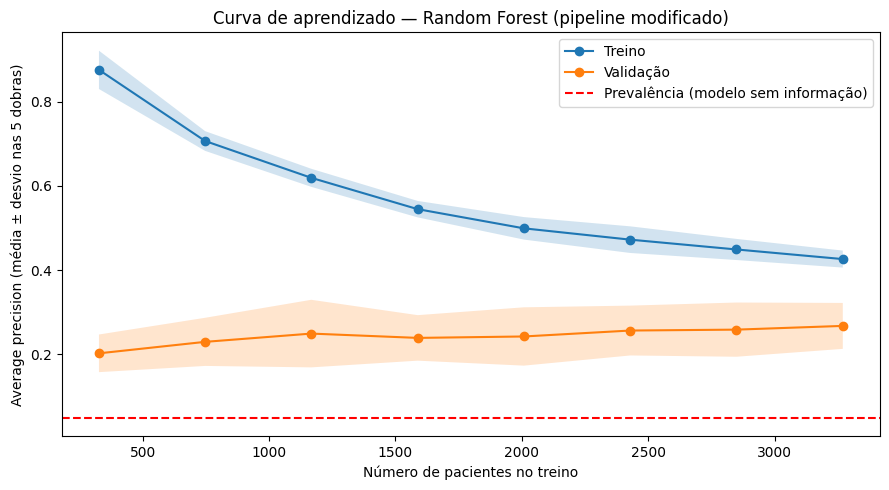

Com todo o treino: AP treino 0.4262 · validação 0.2673 · distância 0.1589


In [276]:
tamanhos, ap_treino, ap_valid = learning_curve(
    melhor_modelo, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
    cv=cv, scoring=METRICA, n_jobs=-1, shuffle=True, random_state=42)

plt.figure(figsize=(9, 5))
for valores, rotulo in [(ap_treino, "Treino"), (ap_valid, "Validação")]:
    media, desvio = valores.mean(axis=1), valores.std(axis=1)
    plt.plot(tamanhos, media, "o-", label=rotulo)
    plt.fill_between(tamanhos, media - desvio, media + desvio, alpha=0.2)
plt.axhline(y_train.mean(), color="r", linestyle="--", label="Prevalência (modelo sem informação)")
plt.title(f"Curva de aprendizado — {nome_melhor}")
plt.xlabel("Número de pacientes no treino")
plt.ylabel("Average precision (média ± desvio nas 5 dobras)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Com todo o treino: AP treino {ap_treino[-1].mean():.4f} · validação {ap_valid[-1].mean():.4f}"
      f" · distância {ap_treino[-1].mean() - ap_valid[-1].mean():.4f}")

# Parte 6 — Avaliação do melhor modelo no conjunto de teste

## 6.1 Limiar de decisão

O modelo prevê probabilidades, mas as métricas pedidas (accuracy, precision, recall e F1) precisam de um corte. O limiar é escolhido **só com o treino**, pelas probabilidades fora da dobra, maximizando o F2. O F2 dá mais peso à revocação, porque deixar de detectar um AVC custa mais que um alarme falso (seção 4.4).

In [277]:
proba_oof_melhor = cross_val_predict(melhor_modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
grade_limiares = np.arange(0.02, 0.81, 0.01)
f2_por_limiar = [fbeta_score(y_train, (proba_oof_melhor >= t).astype(int), beta=2) for t in grade_limiares]
limiar_final = grade_limiares[int(np.argmax(f2_por_limiar))]
print(f"Limiar escolhido (maior F2 fora da dobra): {limiar_final:.2f}")

Limiar escolhido (maior F2 fora da dobra): 0.08


## 6.2 Métricas no teste

O teste é usado aqui pela primeira vez para o melhor modelo. Mostramos o limiar escolhido e, para comparação, o limiar padrão de 0,5.

In [278]:
melhor_modelo.fit(X_train, y_train)
proba_final = melhor_modelo.predict_proba(X_test)[:, 1]

linhas_teste = []
for rotulo, t in [(f"limiar {limiar_final:.2f} (F2)", limiar_final), ("limiar 0,50 (padrão)", 0.5)]:
    pred = (proba_final >= t).astype(int)
    linhas_teste.append({"limiar": rotulo,
                         "Accuracy": accuracy_score(y_test, pred),
                         "Precision": precision_score(y_test, pred, zero_division=0),
                         "Recall": recall_score(y_test, pred),
                         "F1-score": f1_score(y_test, pred),
                         "F2": fbeta_score(y_test, pred, beta=2)})
tabela_teste = pd.DataFrame(linhas_teste).set_index("limiar")
display(tabela_teste.round(4))

print(f"ROC-AUC no teste:           {roc_auc_score(y_test, proba_final):.4f}")
print(f"Average precision no teste: {average_precision_score(y_test, proba_final):.4f}"
      f"   (prevalência {y_test.mean():.4f})")

,Accuracy,Precision,Recall,F1-score,F2
limiar,,,,,
limiar 0.08 (F2),0.8151,0.1826,0.8,0.2974,0.4773
"limiar 0,50 (padrão)",0.9511,0.0000,0.0,0.0000,0.0000


ROC-AUC no teste:           0.8442
Average precision no teste: 0.2302   (prevalência 0.0489)


## 6.3 Matriz de confusão

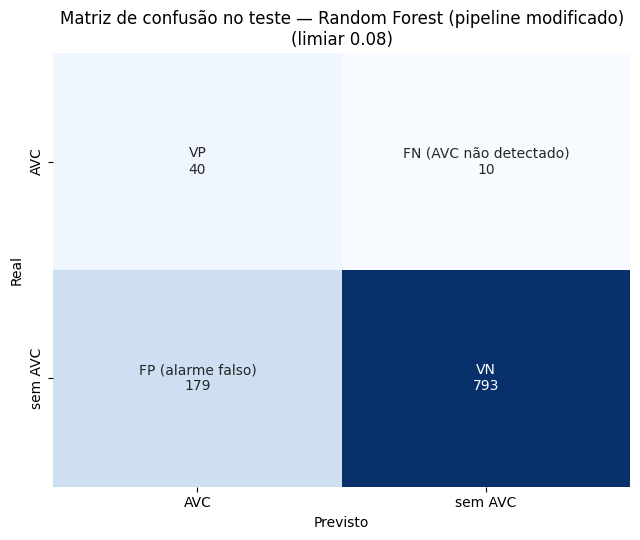

Dos 50 AVCs do teste, o modelo encontrou 40 e deixou passar 10.
Para isso, gerou 179 alarmes falsos entre 972 pacientes sem AVC.


In [279]:
pred_final = (proba_final >= limiar_final).astype(int)
cm_final = confusion_matrix(y_test, pred_final, labels=[1, 0])
tp, fn, fp, tn = cm_final.ravel()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
rotulos = np.array([[f"VP\n{tp}", f"FN (AVC não detectado)\n{fn}"],
                    [f"FP (alarme falso)\n{fp}", f"VN\n{tn}"]])
sns.heatmap(cm_final, annot=rotulos, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["AVC", "sem AVC"], yticklabels=["AVC", "sem AVC"])
ax.set_title(f"Matriz de confusão no teste — {nome_melhor}\n(limiar {limiar_final:.2f})")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

print(f"Dos {tp + fn} AVCs do teste, o modelo encontrou {tp} e deixou passar {fn}.")
print(f"Para isso, gerou {fp} alarmes falsos entre {fp + tn} pacientes sem AVC.")

## 6.4 Curva ROC e ROC-AUC

A curva ROC mostra a taxa de verdadeiros positivos (revocação) contra a taxa de falsos positivos em todos os limiares. O ponto marcado é o limiar escolhido.

Como o AVC é raro, também mostramos a curva precisão-revocação, que corresponde à métrica de seleção (AP).

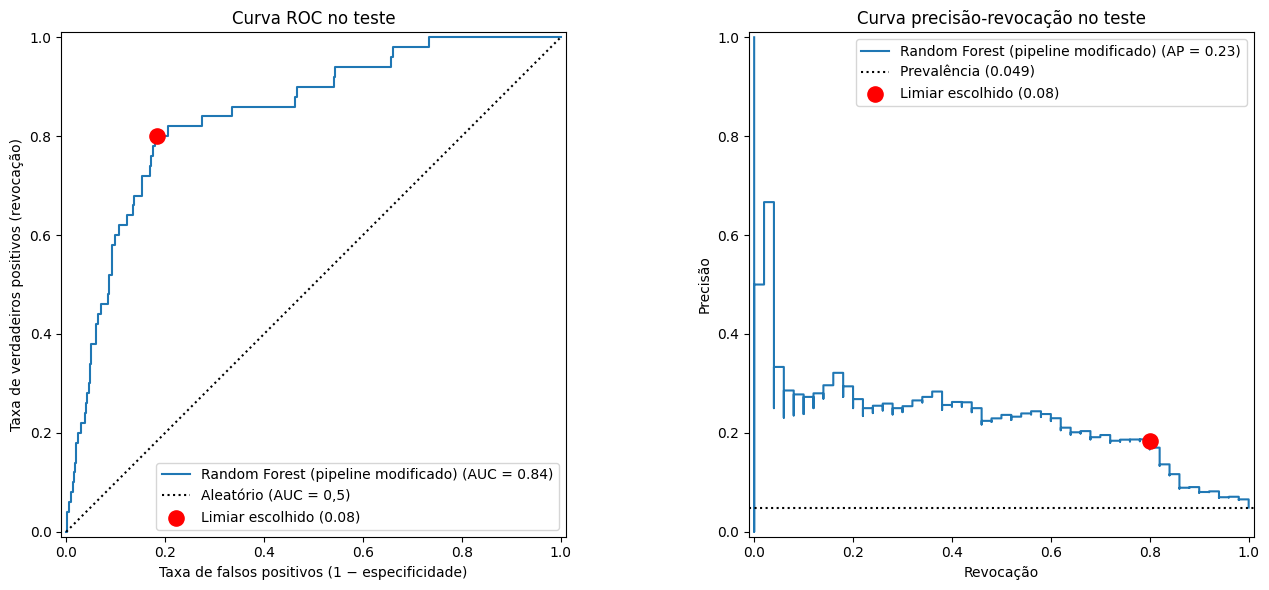

In [280]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

RocCurveDisplay.from_predictions(y_test, proba_final, name=nome_melhor, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k:", label="Aleatório (AUC = 0,5)")
axes[0].scatter(fp / (fp + tn), tp / (tp + fn), s=120, color="r", zorder=5,
                label=f"Limiar escolhido ({limiar_final:.2f})")
axes[0].set_title("Curva ROC no teste")
axes[0].set_xlabel("Taxa de falsos positivos (1 − especificidade)")
axes[0].set_ylabel("Taxa de verdadeiros positivos (revocação)")
axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_test, proba_final, name=nome_melhor, ax=axes[1])
axes[1].axhline(y_test.mean(), color="k", linestyle=":", label=f"Prevalência ({y_test.mean():.3f})")
axes[1].scatter(tp / (tp + fn), tp / max(tp + fp, 1), s=120, color="r", zorder=5,
                label=f"Limiar escolhido ({limiar_final:.2f})")
axes[1].set_title("Curva precisão-revocação no teste")
axes[1].set_xlabel("Revocação")
axes[1].set_ylabel("Precisão")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

**Como ler:**
- **ROC-AUC** é a probabilidade de o modelo dar um escore maior a um paciente com AVC do que a um sem AVC, ambos sorteados ao acaso. 0,5 é o acaso e 1 é perfeito.
- A curva precisão-revocação fica bem abaixo da ROC. Com ~5% de prevalência, mesmo uma boa separação gera muitos falsos positivos para cada AVC encontrado.

# Parte 7 — Interpretação e explicabilidade

## 7.1 Modelo linear: as 3 features de maior coeficiente

Usamos a melhor logística da seção 5.2. As numéricas foram padronizadas, então os coeficientes são comparáveis:
- **Numéricas:** o coeficiente é a variação no log da chance de AVC para +1 desvio padrão.
- **Categóricas:** o coeficiente compara a categoria com a de referência.

A magnitude é o valor absoluto do coeficiente.

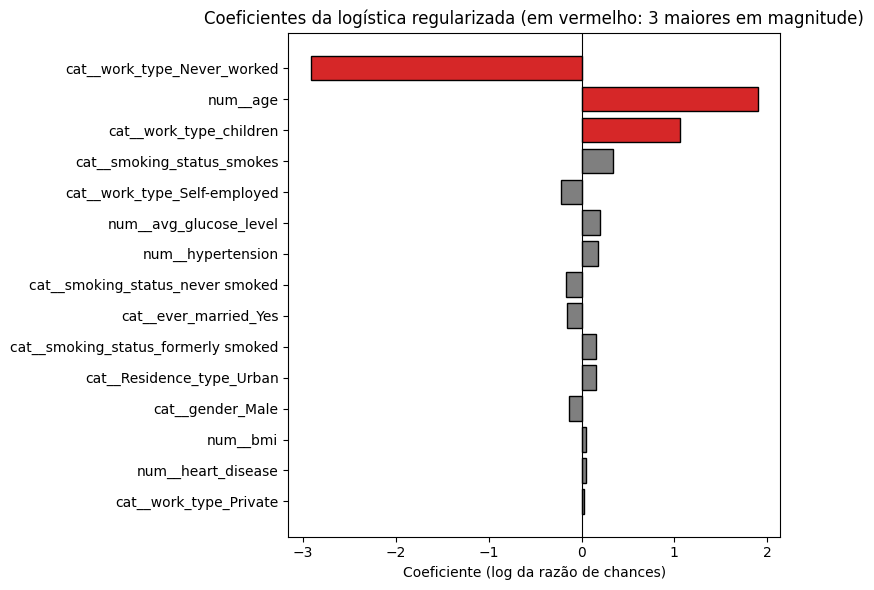

cat__work_type_Never_worked: coef = -2.920 -> pertencer a esta categoria diminui a chance de AVC (x 0.05)
num__age: coef = +1.898 -> +1 desvio padrão aumenta a chance de AVC (x 6.67)
cat__work_type_children: coef = +1.061 -> pertencer a esta categoria aumenta a chance de AVC (x 2.89)


In [281]:
modelo_linear = busca_log.best_estimator_
nomes_lin = modelo_linear.named_steps["preprocessor"].get_feature_names_out()
coef_lin = pd.Series(modelo_linear.named_steps["classificador"].coef_[0], index=nomes_lin)
top3_lin = coef_lin.abs().sort_values(ascending=False).head(3).index

ordem = coef_lin.reindex(coef_lin.abs().sort_values().index)
cores = ["tab:red" if nome in top3_lin else "tab:gray" for nome in ordem.index]
plt.figure(figsize=(8, 6))
plt.barh(ordem.index, ordem.values, color=cores, edgecolor="black")
plt.axvline(0, color="black", lw=0.8)
plt.title("Coeficientes da logística regularizada (em vermelho: 3 maiores em magnitude)")
plt.xlabel("Coeficiente (log da razão de chances)")
plt.tight_layout()
plt.show()

for nome in top3_lin:
    c = coef_lin[nome]
    direcao = "aumenta" if c > 0 else "diminui"
    unidade = "+1 desvio padrão" if nome.startswith("num") else "pertencer a esta categoria"
    print(f"{nome}: coef = {c:+.3f} -> {unidade} {direcao} a chance de AVC (x {np.exp(c):.2f})")

**Análise:** os efeitos valem **mantendo as outras variáveis fixas**, e são associações, não causas.

Com regularização L1, coeficientes zerados indicam variáveis que o modelo dispensou. Uma variável correlacionada com outra, por exemplo `ever_married` e `age`, pode ter o coeficiente encolhido porque a outra já carrega a informação.

## 7.2 Modelo ensemble: as 3 features mais importantes

Usamos a melhor Random Forest da seção 5.3, com duas medidas de importância:
- **MDI (`feature_importances_`):** quanto cada variável reduz a impureza nas divisões das árvores. É calculada no treino e tende a favorecer variáveis contínuas com muitos valores possíveis.
- **Importância por permutação, no teste:** quanto a AP cai quando os valores de uma variável são embaralhados. Por ser medida em dados novos, é mais confiável. Ela é calculada nas colunas originais, antes do one-hot.

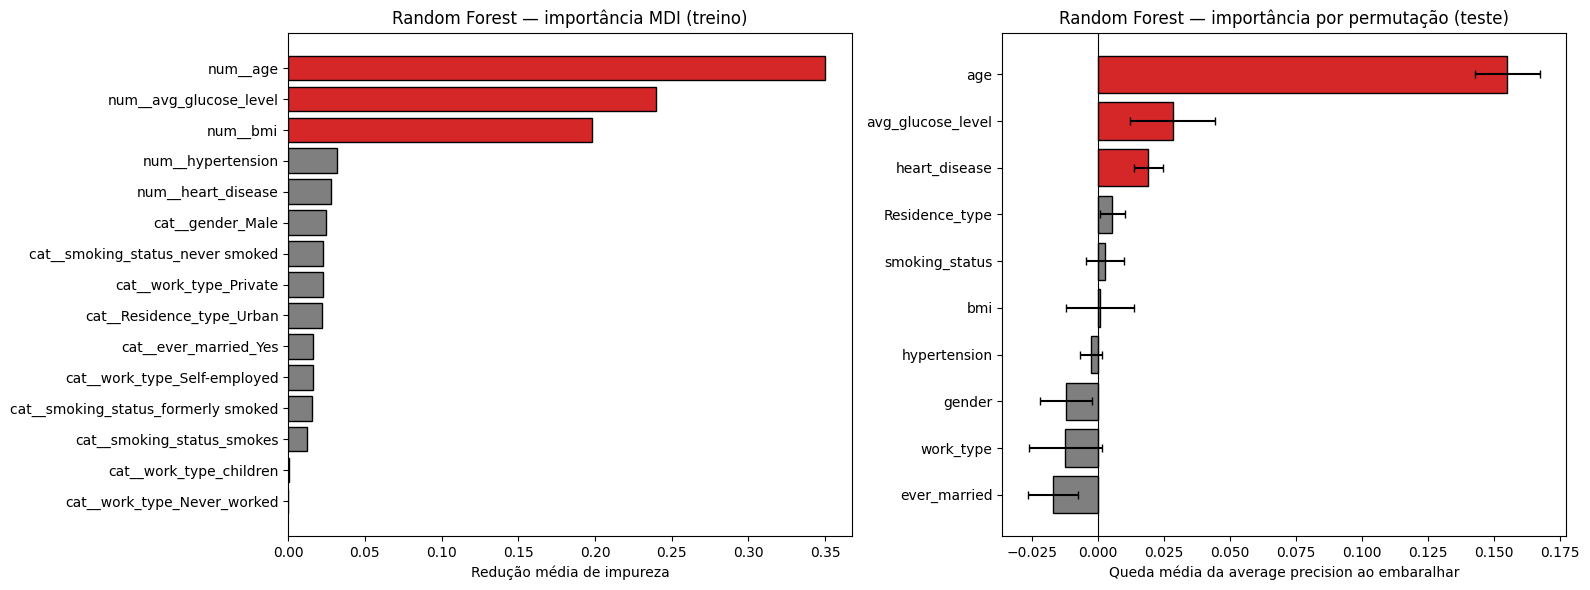

Top 3 MDI:        ['num__age', 'num__avg_glucose_level', 'num__bmi']
Top 3 permutação: ['age', 'avg_glucose_level', 'heart_disease']


In [282]:
from sklearn.inspection import permutation_importance

modelo_rf = busca_rf.best_estimator_
nomes_rf = modelo_rf.named_steps["preprocessor"].get_feature_names_out()
mdi = pd.Series(modelo_rf.named_steps["classificador"].feature_importances_, index=nomes_rf).sort_values()

perm = permutation_importance(modelo_rf, X_test, y_test, scoring=METRICA, n_repeats=10,
                              random_state=42, n_jobs=-1)
perm_media = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
perm_desvio = pd.Series(perm.importances_std, index=X_test.columns).reindex(perm_media.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(mdi.index, mdi.values, color=["tab:red" if n in mdi.index[-3:] else "tab:gray" for n in mdi.index],
             edgecolor="black")
axes[0].set_title("Random Forest — importância MDI (treino)")
axes[0].set_xlabel("Redução média de impureza")

axes[1].barh(perm_media.index, perm_media.values, xerr=perm_desvio.values, capsize=3,
             color=["tab:red" if n in perm_media.index[-3:] else "tab:gray" for n in perm_media.index],
             edgecolor="black")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Random Forest — importância por permutação (teste)")
axes[1].set_xlabel("Queda média da average precision ao embaralhar")
plt.tight_layout()
plt.show()

print("Top 3 MDI:       ", list(mdi.index[-3:][::-1]))
print("Top 3 permutação:", list(perm_media.index[-3:][::-1]))

**Análise:**
- Variáveis que aparecem no top 3 das duas medidas são importantes de forma robusta.
- Uma variável alta na MDI e perto de zero na permutação é sinal de que a árvore a usou para decorar o treino, sem ganho em dados novos.
- Importância mostra **quanto** o modelo depende de uma variável, não **em que direção** ela muda o risco. A direção aparece no SHAP, a seguir.

## 7.3 SHAP no melhor modelo

O SHAP distribui a previsão de cada paciente entre as variáveis (Lundberg & Lee, 2017). A previsão é igual ao valor base (a previsão média) mais a soma das contribuições de cada variável.
- Na Random Forest, os valores ficam em unidades de probabilidade (`TreeExplainer`).
- Na logística, ficam em log da chance (`LinearExplainer`).

In [283]:
%pip install -q shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\adrie\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [284]:
import shap

pre_melhor = melhor_modelo.named_steps["preprocessor"]
clf_melhor = melhor_modelo.named_steps["classificador"]
nomes_melhor = pre_melhor.get_feature_names_out()
X_test_t = pd.DataFrame(pre_melhor.transform(X_test), columns=nomes_melhor, index=X_test.index).astype(float)
X_train_t = pd.DataFrame(pre_melhor.transform(X_train), columns=nomes_melhor, index=X_train.index).astype(float)

if isinstance(clf_melhor, RandomForestClassifier):
    explainer = shap.TreeExplainer(clf_melhor)
else:
    explainer = shap.LinearExplainer(clf_melhor, X_train_t)
valores_shap = explainer(X_test_t)
if valores_shap.values.ndim == 3:                      # Random Forest: fica só com a classe 1 (AVC)
    valores_shap = valores_shap[:, :, 1]
print("Valores SHAP:", valores_shap.values.shape)

Valores SHAP: (1022, 16)


### Importância global

- **Gráfico de barras:** a média de |SHAP| de cada variável, ou seja, quanto ela move a previsão em média.
- **Beeswarm:** cada ponto é um paciente. A cor é o valor da variável (vermelho = alto) e a posição é o efeito na previsão (à direita = aumenta o risco).

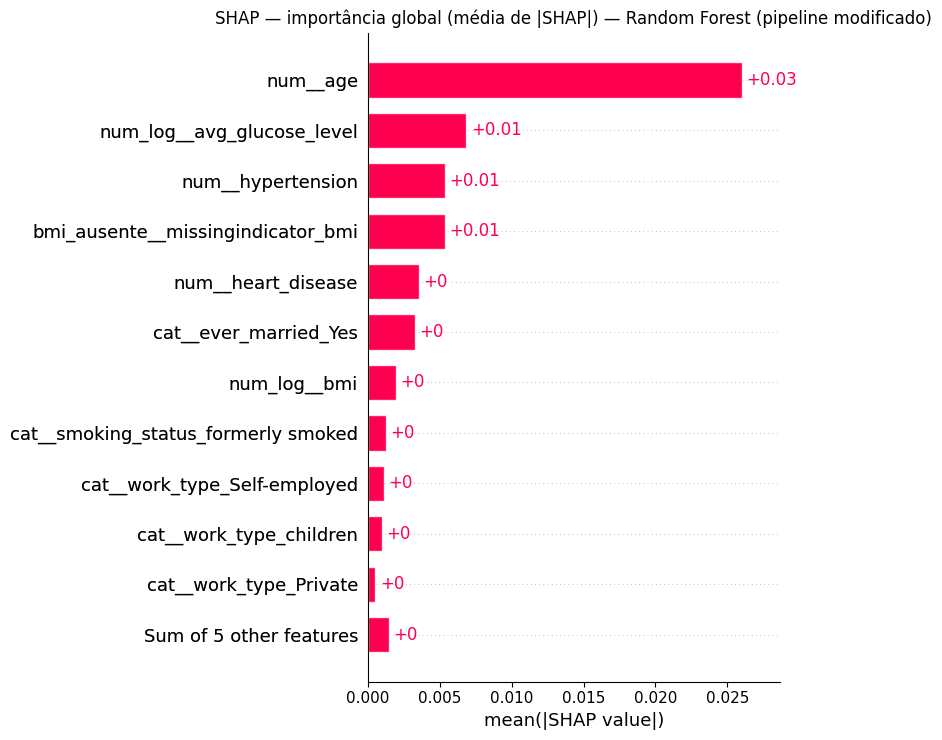

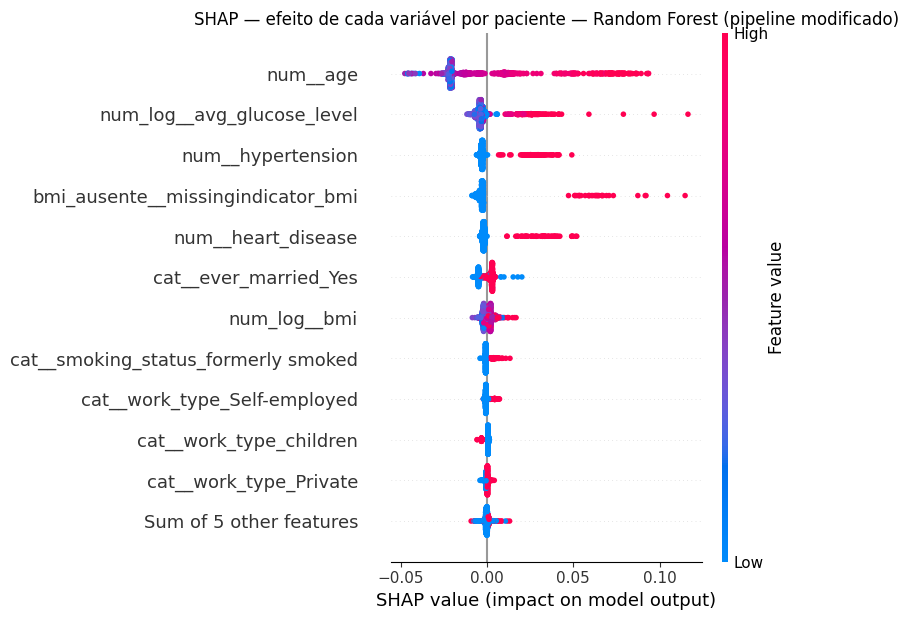

In [285]:
shap.plots.bar(valores_shap, max_display=12, show=False)
plt.title(f"SHAP — importância global (média de |SHAP|) — {nome_melhor}")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(valores_shap, max_display=12, show=False)
plt.title(f"SHAP — efeito de cada variável por paciente — {nome_melhor}")
plt.tight_layout()
plt.show()

### Explicação de 3 predições individuais

Escolhemos três pacientes do teste que representam situações diferentes:
1. **Verdadeiro positivo:** o paciente com AVC que recebeu o maior risco.
2. **Falso negativo:** o paciente com AVC que recebeu o menor risco, ou seja, o caso que o modelo mais deixa passar.
3. **Falso positivo:** o paciente sem AVC que recebeu o maior risco, ou seja, o alarme falso mais forte.

O gráfico em cascata (waterfall) parte do valor base e soma a contribuição de cada variável até chegar à previsão.


=== Verdadeiro positivo (AVC, maior risco previsto) ===
gender                  Male
age                     81.0
hypertension               1
heart_disease              1
ever_married             Yes
work_type            Private
Residence_type         Urban
avg_glucose_level     250.89
bmi                     28.1
smoking_status        smokes
Probabilidade prevista de AVC: 0.296
3 features que mais contribuíram:
  num_log__avg_glucose_level: +0.0790 (aumenta o risco)
  num__age: +0.0722 (aumenta o risco)
  num__heart_disease: +0.0493 (aumenta o risco)


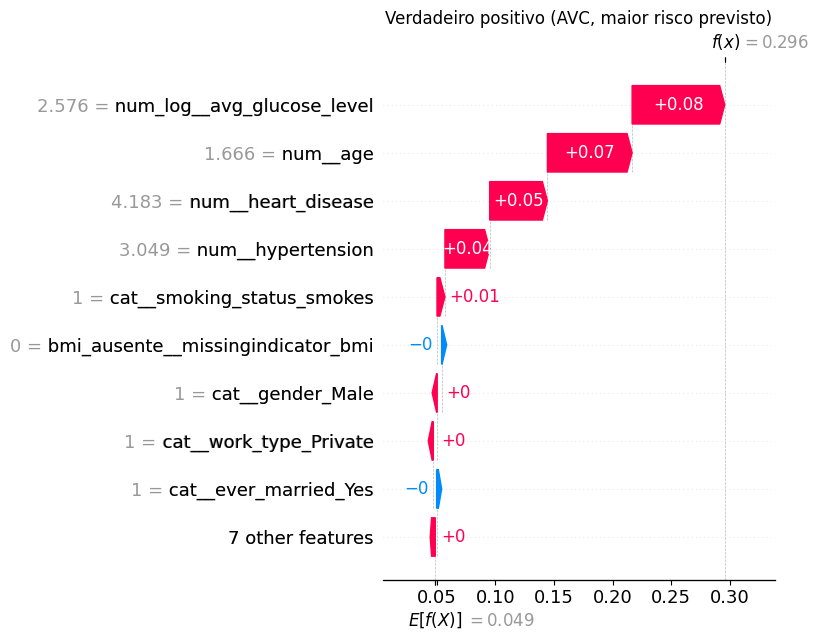


=== Falso negativo (AVC, menor risco previsto) ===
gender                 Female
age                      14.0
hypertension                0
heart_disease               0
ever_married               No
work_type            children
Residence_type          Rural
avg_glucose_level       57.93
bmi                      30.9
smoking_status        Unknown
Probabilidade prevista de AVC: 0.013
3 features que mais contribuíram:
  num__age: -0.0204 (diminui o risco)
  cat__ever_married_Yes: -0.0049 (diminui o risco)
  bmi_ausente__missingindicator_bmi: -0.0038 (diminui o risco)


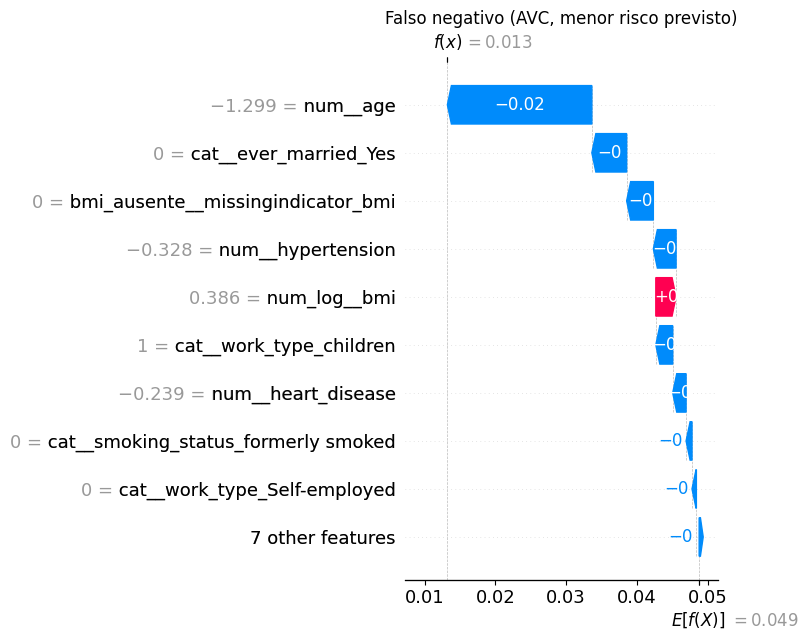


=== Falso positivo (sem AVC, maior risco previsto) ===
gender                       Male
age                          76.0
hypertension                    1
heart_disease                   0
ever_married                  Yes
work_type                 Private
Residence_type              Rural
avg_glucose_level           267.6
bmi                          30.5
smoking_status       never smoked
Probabilidade prevista de AVC: 0.299
3 features que mais contribuíram:
  num_log__avg_glucose_level: +0.1164 (aumenta o risco)
  num__age: +0.0936 (aumenta o risco)
  num__hypertension: +0.0418 (aumenta o risco)


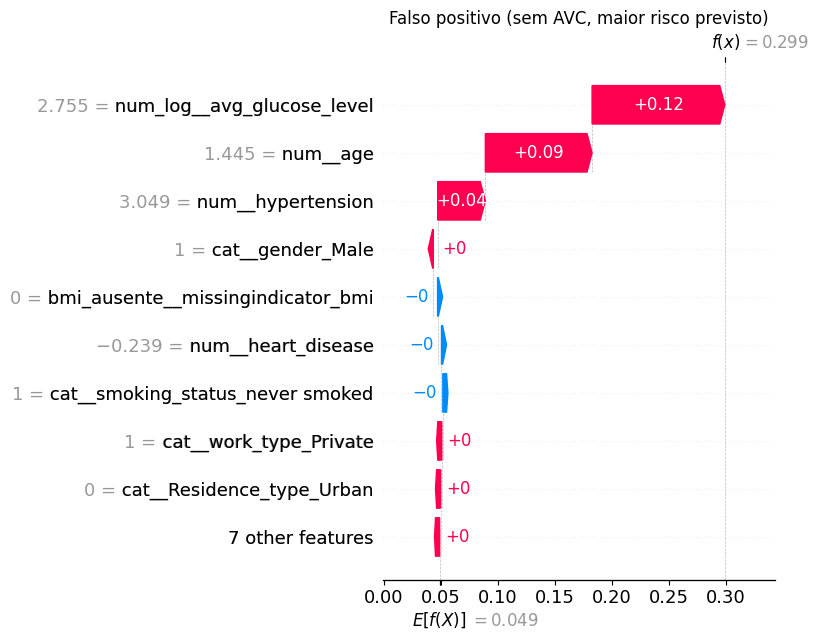

In [286]:
y_teste_arr = y_test.to_numpy()
pos, neg = np.flatnonzero(y_teste_arr == 1), np.flatnonzero(y_teste_arr == 0)
casos = {"Verdadeiro positivo (AVC, maior risco previsto)": pos[np.argmax(proba_final[pos])],
         "Falso negativo (AVC, menor risco previsto)": pos[np.argmin(proba_final[pos])],
         "Falso positivo (sem AVC, maior risco previsto)": neg[np.argmax(proba_final[neg])]}

for titulo, i in casos.items():
    print(f"\n=== {titulo} ===")
    print(X_test.iloc[i].to_string())
    print(f"Probabilidade prevista de AVC: {proba_final[i]:.3f}")
    contrib = pd.Series(valores_shap.values[i], index=nomes_melhor)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
    print("3 features que mais contribuíram:")
    for nome, v in top.items():
        print(f"  {nome}: {v:+.4f} ({'aumenta' if v > 0 else 'diminui'} o risco)")

    shap.plots.waterfall(valores_shap[i], max_display=10, show=False)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

**Análise:**
- No **verdadeiro positivo**, espera-se que idade alta, hipertensão, doença cardíaca ou glicose alta empurrem o risco para cima.
- O **falso negativo** mostra a principal fraqueza do modelo: um paciente com AVC cujo perfil (por exemplo, jovem e sem comorbidades registradas) não se parece com o dos casos típicos. As variáveis disponíveis não capturam o que levou ao AVC dele.
- O **falso positivo** é o oposto: um paciente com perfil de alto risco que não teve AVC no período registrado. Ele pode ser um bom candidato a acompanhamento preventivo.

# Parte 8 — Discussão crítica

## Limitações do melhor modelo

1. **Associação não é causa, e as explicações herdam isso.**
   - O SHAP e os coeficientes mostram como o modelo usa cada variável, não o efeito causal dela sobre o AVC. `ever_married`, por exemplo, só aparece como relevante por estar correlacionada com a idade.
   - Variáveis correlacionadas dividem o crédito de forma arbitrária, então uma explicação SHAP é uma estimativa a ser verificada, não uma justificativa clínica (Lundberg & Lee, 2017; Molnar, 2022).
   - Usar o modelo para recomendar intervenções ("mudar X reduz o risco") seria um erro.
2. **Poucos eventos para o número de parâmetros.**
   - O treino tem cerca de 200 AVCs. Em modelos de predição clínica, o número de eventos por parâmetro determina a estabilidade dos coeficientes e o risco de sobreajuste (Peduzzi et al., 1996; Riley et al., 2020).
   - Com tão poucos positivos, as métricas do teste (~50 AVCs) têm intervalos de confiança largos: um ou dois casos a mais detectados mudam a revocação em vários pontos percentuais.
   - Nenhum dos números reportados deve ser lido como preciso na segunda casa decimal.

## Limitações dos dados

1. **Origem desconhecida e sem documentação.**
   - O dataset do Kaggle é descrito como "confidencial", sem informação sobre o hospital ou país, o período, o critério de inclusão e a forma de diagnóstico do AVC.
   - Sem uma documentação no formato de *datasheet* (Gebru et al., 2021), não dá para saber a quem o modelo se aplica, nem se há vieses de seleção. Também não há validação externa em outra população.
2. **Dados transversais e variáveis clínicas importantes ausentes.**
   - Não há informação temporal: não se sabe se a hipertensão ou o tabagismo foram registrados antes ou depois do AVC. Isso permite causalidade reversa; por exemplo, pacientes que pararam de fumar após o evento.
   - Faltam fatores de risco consolidados, como fibrilação atrial, pressão sistólica medida, colesterol, uso de anti-hipertensivos e histórico familiar, que fazem parte de escores clínicos como o de Framingham (Wolf et al., 1991).
   - `smoking_status = "Unknown"` cobre cerca de 30% dos pacientes.

## Ações para operacionalização e manutenção

1. **Monitoramento contínuo e recalibração.**
   - Em produção, a população atendida muda com o tempo: idade, prevalência, protocolos de medição. Isso degrada o modelo silenciosamente (Sculley et al., 2015).
   - É preciso monitorar a distribuição das variáveis de entrada e das probabilidades previstas. Quando os desfechos reais forem conhecidos, também a AP, a revocação e a calibração.
   - O modelo deve ser recalibrado ou retreinado quando houver desvio. A calibração é o ponto que mais se degrada quando a prevalência muda (Van Calster et al., 2019).
2. **Uso como apoio à decisão, com documentação e governança.**
   - O modelo deve entrar no fluxo clínico como triagem para acompanhamento preventivo, com decisão final do profissional de saúde, nunca como diagnóstico automático.
   - O limiar deve ser definido junto com a equipe clínica, conforme a capacidade de atendimento a alarmes falsos.
   - O modelo deve ser publicado com um *model card* (Mitchell et al., 2019): dados de treino, métricas por subgrupo (sexo, faixa etária), limitações e uso pretendido.
   - Como envolve dados de saúde, o uso precisa respeitar a LGPD (Lei 13.709/2018), incluindo o direito do paciente à revisão de decisões automatizadas (art. 20).

## Referências

- Bergstra, J.; Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Brasil. Lei nº 13.709, de 14 de agosto de 2018. Lei Geral de Proteção de Dados Pessoais (LGPD).
- Gebru, T. et al. (2021). Datasheets for datasets. *Communications of the ACM*, 64(12), 86–92. https://doi.org/10.1145/3458723
- Lundberg, S. M.; Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- Mitchell, M. et al. (2019). Model cards for model reporting. *Proceedings of the Conference on Fairness, Accountability, and Transparency (FAT\* '19)*, 220–229. https://doi.org/10.1145/3287560.3287596
- Molnar, C. (2022). *Interpretable Machine Learning* (2ª ed.). https://christophm.github.io/interpretable-ml-book/
- Peduzzi, P. et al. (1996). A simulation study of the number of events per variable in logistic regression analysis. *Journal of Clinical Epidemiology*, 49(12), 1373–1379. https://doi.org/10.1016/S0895-4356(96)00236-3
- Riley, R. D. et al. (2020). Calculating the sample size required for developing a clinical prediction model. *BMJ*, 368, m441. https://doi.org/10.1136/bmj.m441
- Saito, T.; Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems*, 28.
- Van Calster, B. et al. (2019). Calibration: the Achilles heel of predictive analytics. *BMC Medicine*, 17, 230. https://doi.org/10.1186/s12916-019-1466-7
- Wolf, P. A. et al. (1991). Probability of stroke: a risk profile from the Framingham Study. *Stroke*, 22(3), 312–318. https://doi.org/10.1161/01.STR.22.3.312

In [287]:
# Resumo final: métrica de seleção (validação) de cada modelo e desempenho do melhor no teste
resumo = pd.DataFrame({
    "AP validação (sem ajuste)": tabela_base["AP validação"].rename(
        {"Logística L2 (C=1)": "Logística regularizada", "Random Forest (padrão)": "Random Forest"}),
    "AP validação (ajustado)": tabela_ajustada["AP validação"],
})
display(resumo.round(4))
print(f"Melhor modelo: {nome_melhor}")
print(f"Teste (limiar {limiar_final:.2f}):")
display(tabela_teste.iloc[[0]].round(4))

,AP validação (sem ajuste),AP validação (ajustado)
Dummy (prevalência),0.0487,0.0487
Logística regularizada,0.1925,0.1934
Random Forest,0.1727,0.2144


Melhor modelo: Random Forest (pipeline modificado)
Teste (limiar 0.08):


,Accuracy,Precision,Recall,F1-score,F2
limiar,,,,,
limiar 0.08 (F2),0.8151,0.1826,0.8,0.2974,0.4773
